In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Environment ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment ready!
Pandas version: 3.0.6
NumPy version: 2.5.3


In [7]:
DATA_PATH = "../data/raw/ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [9]:
rows, columns = df.shape

print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")

Number of rows: 10000
Number of columns: 14


In [10]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i:2}. {column}")

 1. UDI
 2. Product ID
 3. Type
 4. Air temperature [K]
 5. Process temperature [K]
 6. Rotational speed [rpm]
 7. Torque [Nm]
 8. Tool wear [min]
 9. Machine failure
10. TWF
11. HDF
12. PWF
13. OSF
14. RNF


## Data Quality Assessment

Before performing exploratory analysis or model development, the dataset is examined for missing values, duplicate observations, data types, feature cardinality, and potential data-quality issues.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [12]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
df.nunique().sort_values()

PWF                            2
HDF                            2
RNF                            2
OSF                            2
TWF                            2
Machine failure                2
Type                           3
Process temperature [K]       82
Air temperature [K]           93
Tool wear [min]              246
Torque [Nm]                  577
Rotational speed [rpm]       941
Product ID                 10000
UDI                        10000
dtype: int64

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


# Exploratory Data Analysis

The objective of this analysis is to understand the distribution of machine operating conditions, identify class imbalance, investigate relationships between physical variables, and determine which conditions are associated with machine failure.

## 1. Machine Failure Distribution

In [16]:
failure_counts = df["Machine failure"].value_counts().sort_index()

print("Non-failure observations:", failure_counts[0])
print("Failure observations:", failure_counts[1])

failure_percentage = (
    df["Machine failure"].value_counts(normalize=True).sort_index() * 100
)

print("\nPercentage distribution:")
print(failure_percentage)

Non-failure observations: 9661
Failure observations: 339

Percentage distribution:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


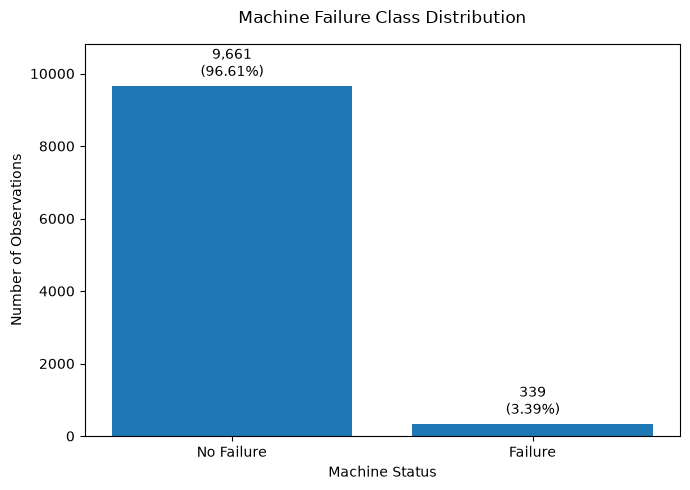

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Failure", "Failure"],
    failure_counts.values
)

ax.set_title("Machine Failure Class Distribution", pad=15)
ax.set_xlabel("Machine Status")
ax.set_ylabel("Number of Observations")

# Give annotations some space above the tallest bar
ax.set_ylim(0, failure_counts.max() * 1.12)

for bar, count in zip(bars, failure_counts.values):
    percentage = count / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + failure_counts.max() * 0.015,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Observation

The target variable is strongly imbalanced. Out of 10,000 observations, 9,661 (96.61%) correspond to normal machine operation, while only 339 (3.39%) represent machine failures.

Therefore, classification accuracy alone would be misleading. A naive classifier predicting "no failure" for every observation would achieve 96.61% accuracy while detecting none of the actual failures.

For this reason, later model evaluation will emphasize recall, precision, F1-score and precision-recall performance in addition to accuracy.

## 2. Sensor Behavior vs. Machine Failure

The following analysis compares operating conditions between normal and failed machines to determine whether failures are associated with identifiable changes in temperature, rotational speed, torque, or tool wear.

In [18]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df.groupby("Machine failure")[sensor_features].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


In [19]:
df.groupby("Machine failure")[sensor_features].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


In [20]:
normal_means = df[df["Machine failure"] == 0][sensor_features].mean()
failure_means = df[df["Machine failure"] == 1][sensor_features].mean()

mean_comparison = pd.DataFrame({
    "Normal": normal_means,
    "Failure": failure_means
})

mean_comparison["Absolute Difference"] = (
    mean_comparison["Failure"] - mean_comparison["Normal"]
)

mean_comparison["Percent Difference"] = (
    mean_comparison["Absolute Difference"]
    / mean_comparison["Normal"]
    * 100
)

mean_comparison.round(2)

,Normal,Failure,Absolute Difference,Percent Difference
Air temperature [K],299.97,300.89,0.91,0.30
Process temperature [K],310.00,310.29,0.29,0.10
Rotational speed [rpm],1540.26,1496.49,-43.77,-2.84
Torque [Nm],39.63,50.17,10.54,26.59
Tool wear [min],106.69,143.78,37.09,34.76


## 3. Physics-Informed Feature Engineering

Rotational speed and torque jointly determine the mechanical power transmitted by a rotating system. Rather than analyzing these variables only independently, mechanical power is derived using the physical relationship between torque and angular velocity.

Angular velocity:

\[
\omega = \frac{2\pi N}{60}
\]

Mechanical power:

\[
P = \tau\omega
\]

where \(N\) is rotational speed in RPM and \(\tau\) is torque in N·m.

In [21]:
df["Angular velocity [rad/s]"] = (
    2 * np.pi * df["Rotational speed [rpm]"] / 60
)

df["Mechanical power [W]"] = (
    df["Torque [Nm]"] * df["Angular velocity [rad/s]"]
)

df[
    [
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Angular velocity [rad/s]",
        "Mechanical power [W]"
    ]
].head()

,Rotational speed [rpm],Torque [Nm],Angular velocity [rad/s],Mechanical power [W]
0,1551,42.8,162.420340,6951.590560
1,1408,46.3,147.445415,6826.722724
2,1498,49.4,156.870193,7749.387543
3,1433,39.5,150.063409,5927.504659
4,1408,40.0,147.445415,5897.816608


In [22]:
df["Temperature difference [K]"] = (
    df["Process temperature [K]"]
    - df["Air temperature [K]"]
)

In [23]:
engineering_features = [
    "Mechanical power [W]",
    "Temperature difference [K]"
]

df.groupby("Machine failure")[engineering_features].mean().T

Machine failure,0,1
Mechanical power [W],6244.547534,7282.819485
Temperature difference [K],10.021571,9.403835


### Engineering Interpretation

Failed machine observations exhibit higher average mechanical power than normal observations.

- Normal operation: approximately **6.24 kW**
- Failure observations: approximately **7.28 kW**
- Average increase during failure observations: approximately **16.6%**

This derived feature combines rotational speed and torque using a physically meaningful relationship rather than treating both measurements independently.

The average process-to-air temperature difference is slightly lower for failed observations (approximately 9.40 K) than for normal observations (approximately 10.02 K).

These differences represent associations rather than causal relationships. Further distributional and failure-mode analysis is required before determining their predictive usefulness.

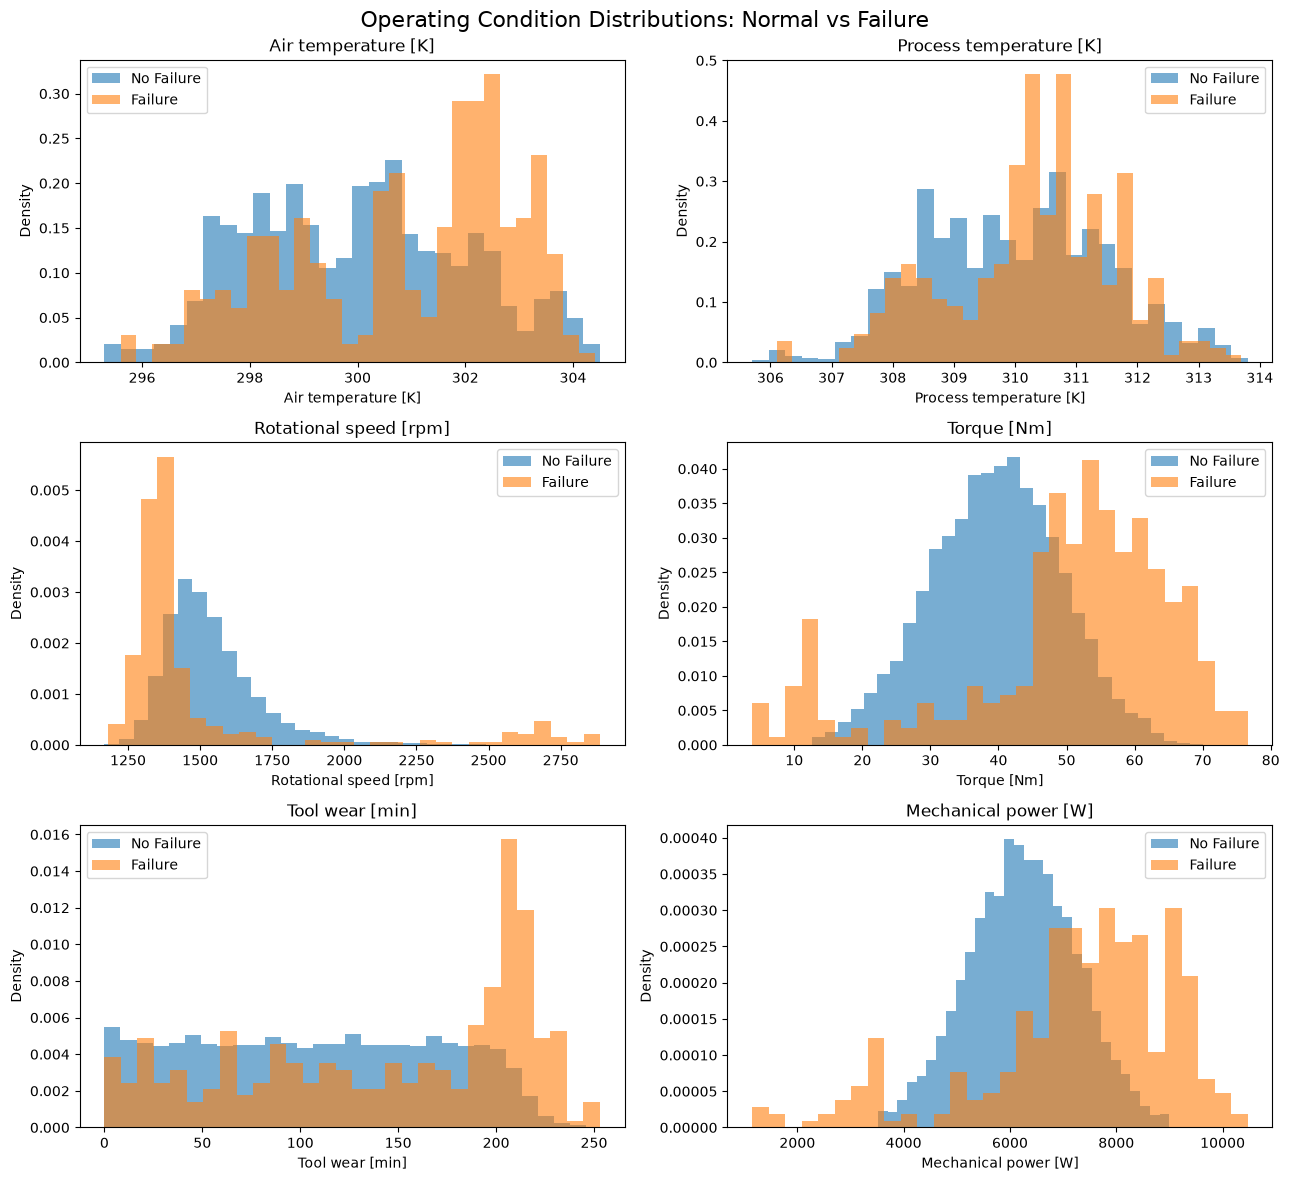

In [24]:
features_to_plot = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]"
]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))

axes = axes.flatten()

for ax, feature in zip(axes, features_to_plot):

    normal = df.loc[df["Machine failure"] == 0, feature]
    failure = df.loc[df["Machine failure"] == 1, feature]

    ax.hist(
        normal,
        bins=30,
        alpha=0.6,
        density=True,
        label="No Failure"
    )

    ax.hist(
        failure,
        bins=30,
        alpha=0.6,
        density=True,
        label="Failure"
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle(
    "Operating Condition Distributions: Normal vs Failure",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 4. Failure Mode Analysis

Machine failure is not generated by a single physical mechanism. The dataset contains indicators for several failure modes:

- TWF — Tool Wear Failure
- HDF — Heat Dissipation Failure
- PWF — Power Failure
- OSF — Overstrain Failure
- RNF — Random Failure

These indicators are analyzed for diagnostic understanding but will not be used as predictors for the primary machine-failure classification model because they contain direct information about the failure outcome.

In [25]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_mode_counts = df[failure_modes].sum()

failure_mode_counts.sort_values(ascending=False)

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [26]:
failure_mode_summary = pd.DataFrame({
    "Count": failure_mode_counts,
    "Percentage of Dataset": failure_mode_counts / len(df) * 100
})

failure_mode_summary.sort_values("Count", ascending=False)

,Count,Percentage of Dataset
HDF,115,1.15
OSF,98,0.98
PWF,95,0.95
TWF,46,0.46
RNF,19,0.19


In [27]:
failure_mode_total = df[failure_modes].sum(axis=1)

pd.crosstab(
    df["Machine failure"],
    failure_mode_total,
    rownames=["Machine Failure"],
    colnames=["Number of Active Failure Modes"]
)

Number of Active Failure Modes,0,1,2,3
Machine Failure,,,,
0,9643,18,0,0
1,9,306,23,1


### Failure-Mode Operating Characteristics

To understand the physical conditions associated with different failure mechanisms, sensor and engineered features are compared across each recorded failure mode.

In [28]:
analysis_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]"
]

mode_profiles = {}

for mode in failure_modes:
    mode_profiles[mode] = df.loc[
        df[mode] == 1,
        analysis_features
    ].mean()

mode_profiles_df = pd.DataFrame(mode_profiles).T

mode_profiles_df.round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical power [W],Temperature difference [K]
TWF,300.30,310.17,1566.17,37.84,216.37,6019.33,9.87
HDF,302.56,310.79,1337.26,53.17,107.19,7433.17,8.23
PWF,300.08,309.95,1763.97,48.51,101.88,7251.82,9.88
OSF,300.04,310.07,1350.33,58.37,207.69,8230.22,10.03
RNF,300.82,310.76,1485.00,43.67,124.47,6685.70,9.95


In [29]:
df["Wear-load interaction"] = (
    df["Tool wear [min]"] * df["Torque [Nm]"]
)

In [30]:
analysis_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]",
    "Wear-load interaction"
]

In [31]:
mode_profiles = {}

for mode in failure_modes:
    mode_profiles[mode] = df.loc[
        df[mode] == 1,
        analysis_features
    ].mean()

mode_profiles_df = pd.DataFrame(mode_profiles).T

mode_profiles_df.round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical power [W],Temperature difference [K],Wear-load interaction
TWF,300.30,310.17,1566.17,37.84,216.37,6019.33,9.87,8188.77
HDF,302.56,310.79,1337.26,53.17,107.19,7433.17,8.23,5702.38
PWF,300.08,309.95,1763.97,48.51,101.88,7251.82,9.88,5018.71
OSF,300.04,310.07,1350.33,58.37,207.69,8230.22,10.03,12066.99
RNF,300.82,310.76,1485.00,43.67,124.47,6685.70,9.95,5334.27


### Failure-Mode Interpretation

The failure-mode analysis indicates that machine failure is associated with multiple distinct operating regimes rather than a single universal sensor pattern.

- **TWF (Tool Wear Failure):** characterized primarily by high accumulated tool wear.
- **HDF (Heat Dissipation Failure):** associated with high ambient temperature, reduced process-to-air temperature difference, and relatively low rotational speed.
- **PWF (Power Failure):** associated with distinctive speed, torque, and mechanical-power operating conditions.
- **OSF (Overstrain Failure):** characterized by high torque, high tool wear, high mechanical power, and a particularly large wear-load interaction.
- **RNF (Random Failure):** does not exhibit an equally clear operating signature; interpretation is also limited by its small sample size.

These results support the use of physics-informed interaction features while also suggesting that nonlinear machine-learning models may be useful for capturing multiple failure regimes.

## 5. Correlation Analysis

Correlation analysis is used to examine linear relationships among numerical sensor measurements, engineered features, and machine failure.

Correlation does not imply causation, and weak correlation does not necessarily imply that a feature is unimportant. Nonlinear relationships and interactions may still provide predictive information.

In [32]:
correlation_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]",
    "Wear-load interaction",
    "Machine failure"
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix.round(3)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical power [W],Temperature difference [K],Wear-load interaction,Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,-0.011,-0.700,0.007,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,-0.011,-0.268,0.006,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.806,-0.017,-0.331,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.979,0.007,0.377,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,-0.003,-0.008,0.898,0.105
Mechanical power [W],-0.011,-0.011,-0.806,0.979,-0.003,1.000,0.007,0.369,0.176
Temperature difference [K],-0.700,-0.268,-0.017,0.007,-0.008,0.007,1.000,-0.005,-0.112
Wear-load interaction,0.007,0.006,-0.331,0.377,0.898,0.369,-0.005,1.000,0.190
Machine failure,0.083,0.036,-0.044,0.191,0.105,0.176,-0.112,0.190,1.000


In [33]:
failure_correlations = (
    correlation_matrix["Machine failure"]
    .drop("Machine failure")
    .sort_values()
)

failure_correlations

Temperature difference [K]   -0.111676
Rotational speed [rpm]       -0.044188
Process temperature [K]       0.035946
Air temperature [K]           0.082556
Tool wear [min]               0.105448
Mechanical power [W]          0.176039
Wear-load interaction         0.190427
Torque [Nm]                   0.191321
Name: Machine failure, dtype: float64

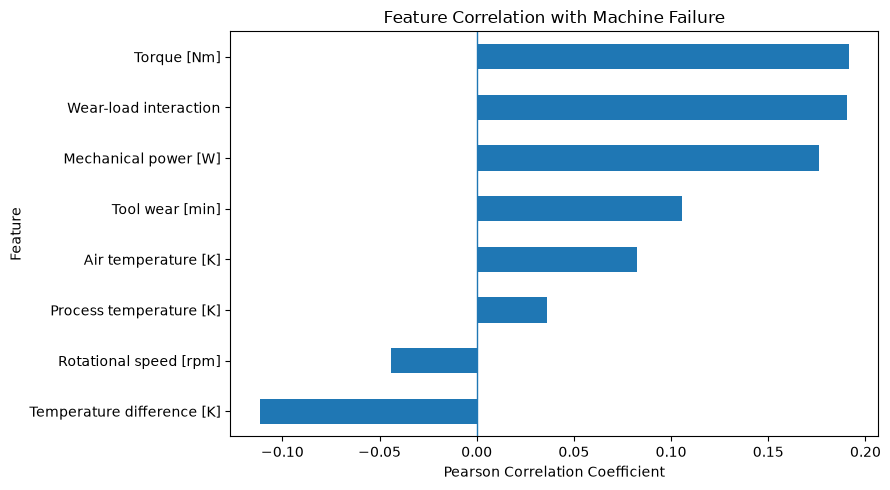

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))

failure_correlations.plot(
    kind="barh",
    ax=ax
)

ax.axvline(0, linewidth=1)

ax.set_title("Feature Correlation with Machine Failure")
ax.set_xlabel("Pearson Correlation Coefficient")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

### Correlation Interpretation

Torque, wear-load interaction, and mechanical power show the strongest positive linear associations with machine failure, while temperature difference shows the strongest negative association.

However, all individual Pearson correlations are relatively modest. This does not imply weak predictive value because earlier distribution analysis revealed nonlinear operating regimes and multiple failure mechanisms. Pearson correlation measures linear association and may not capture threshold effects, extreme operating conditions, or interactions between variables.

In [35]:
from scipy.stats import ttest_ind

print("SciPy ready!")

SciPy ready!


In [36]:
statistical_results = []

for feature in correlation_features[:-1]:

    normal = df.loc[
        df["Machine failure"] == 0,
        feature
    ]

    failure = df.loc[
        df["Machine failure"] == 1,
        feature
    ]

    # Welch's independent t-test
    t_stat, p_value = ttest_ind(
        failure,
        normal,
        equal_var=False
    )

    # Pooled standard deviation for Cohen's d
    n_failure = len(failure)
    n_normal = len(normal)

    pooled_std = np.sqrt(
        (
            (n_failure - 1) * failure.var(ddof=1)
            + (n_normal - 1) * normal.var(ddof=1)
        )
        /
        (n_failure + n_normal - 2)
    )

    cohens_d = (
        failure.mean() - normal.mean()
    ) / pooled_std

    statistical_results.append({
        "Feature": feature,
        "Normal Mean": normal.mean(),
        "Failure Mean": failure.mean(),
        "Mean Difference": failure.mean() - normal.mean(),
        "p-value": p_value,
        "Cohen's d": cohens_d
    })

statistical_results_df = pd.DataFrame(statistical_results)

statistical_results_df = statistical_results_df.sort_values(
    "Cohen's d",
    key=abs,
    ascending=False
)

statistical_results_df.round(4)

,Feature,Normal Mean,Failure Mean,Mean Difference,p-value,Cohen's d
3,Torque [Nm],39.6297,50.1681,10.5385,0.0000,1.0770
7,Wear-load interaction,4213.8427,7187.9383,2974.0956,0.0000,1.0718
5,Mechanical power [W],6244.5475,7282.8195,1038.2720,0.0000,0.9881
6,Temperature difference [K],10.0216,9.4038,-0.6177,0.0000,-0.6209
4,Tool wear [min],106.6937,143.7817,37.0880,0.0000,0.5859
0,Air temperature [K],299.9740,300.8864,0.9124,0.0000,0.4577
2,Rotational speed [rpm],1540.2600,1496.4867,-43.7733,0.0376,-0.2444
1,Process temperature [K],309.9956,310.2903,0.2947,0.0001,0.1987


### Statistical Interpretation

Several operating variables show statistically detectable differences between normal and failed machine observations.

Torque exhibits a large standardized difference between the two groups. The engineered wear-load interaction and mechanical-power features also show large effect sizes, supporting their inclusion as candidate predictors.

Temperature difference and tool wear exhibit moderate standardized differences, while air temperature shows a smaller effect.

Very small p-values indicate strong evidence against equal group means, but statistical significance alone does not establish practical importance or causality. Effect size and predictive performance will therefore be considered alongside significance testing.

Engineered features will be retained provisionally and evaluated through model comparison rather than assumed to improve prediction.

## 6. Machine Learning Dataset Preparation

The predictive dataset is constructed using operational sensor variables and selected physics-informed engineered features.

Identifier variables are excluded because they do not represent machine operating conditions.

Failure-mode indicators (TWF, HDF, PWF, OSF, RNF) are excluded from the predictor set to prevent target leakage.

Angular velocity is also excluded because it is a deterministic linear transformation of rotational speed and therefore provides redundant information.

In [37]:
model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]",
    "Wear-load interaction"
]

target = "Machine failure"

X = df[model_features].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (10000, 9)
y shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical power [W],Temperature difference [K],Wear-load interaction
0,M,298.1,308.6,1551,42.8,0,6951.590560,10.5,0.0
1,L,298.2,308.7,1408,46.3,3,6826.722724,10.5,138.9
2,L,298.1,308.5,1498,49.4,5,7749.387543,10.4,247.0
3,L,298.2,308.6,1433,39.5,7,5927.504659,10.4,276.5
4,L,298.2,308.7,1408,40.0,9,5897.816608,10.5,360.0


In [38]:
X["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [39]:
from sklearn.model_selection import train_test_split

print("Scikit-learn ready!")

Scikit-learn ready!


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining failure rate:")
print(y_train.value_counts(normalize=True))

print("\nTesting failure rate:")
print(y_test.value_counts(normalize=True))

Training observations: 8000
Testing observations: 2000

Training failure rate:
Machine failure
0    0.966125
1    0.033875
Name: proportion, dtype: float64

Testing failure rate:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [41]:
random_state=42

### Train-Test Split

The dataset was divided into 80% training data and 20% held-out test data using stratified sampling.

Stratification preserved the original class imbalance, with approximately 3.39% machine failures in both subsets.

A fixed random state was used to ensure reproducibility. The test set will remain held out during model development and will be used for final evaluation rather than model training.

## 7. Machine Learning Pipeline

A reusable preprocessing pipeline is constructed to prevent inconsistencies between training and inference.

- `Type` is treated as a categorical variable and one-hot encoded.
- Numerical variables are standardized using StandardScaler.
- Preprocessing is fitted only on the training data through a scikit-learn Pipeline, helping prevent data leakage.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    "Type"
]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]",
    "Wear-load interaction"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Type']),
                                ('numerical', StandardScaler(),
                                 ['Air temperature [K]',
                                  'Process temperature [K]',
                                  'Rotational speed [rpm]', 'Torque [Nm]',
                                  'Tool wear [min]', 'Mechanical power [W]',
                                  'Temperature difference [K]',
                                  'Wear-load interaction'])])


In [43]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DummyClassifier(strategy="most_frequent")
        )
    ]
)

dummy_pipeline.fit(X_train, y_train)

dummy_predictions = dummy_pipeline.predict(X_test)

dummy_accuracy = accuracy_score(
    y_test,
    dummy_predictions
)

dummy_precision = precision_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

dummy_recall = recall_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

dummy_f1 = f1_score(
    y_test,
    dummy_predictions,
    zero_division=0
)

print(f"Accuracy : {dummy_accuracy:.4f}")
print(f"Precision: {dummy_precision:.4f}")
print(f"Recall   : {dummy_recall:.4f}")
print(f"F1 Score : {dummy_f1:.4f}")

Accuracy : 0.9660
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000


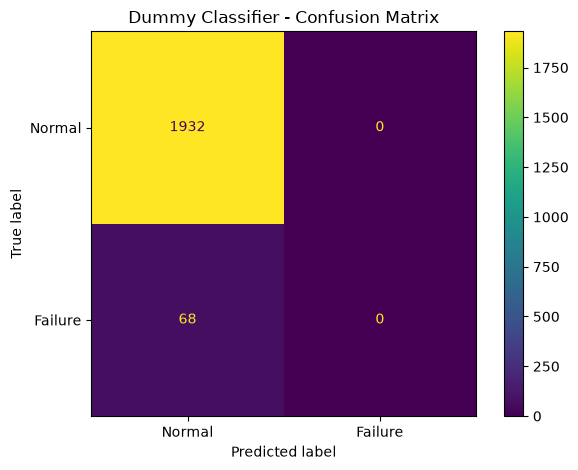

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dummy_predictions,
    display_labels=["Normal", "Failure"],
    values_format="d"
)

plt.title("Dummy Classifier - Confusion Matrix")
plt.tight_layout()
plt.show()

### Dummy Baseline Interpretation

The majority-class dummy classifier achieves approximately 96.6% accuracy because machine failures represent only about 3.4% of the dataset.

However, its precision, recall, and F1-score for the failure class are all zero because it predicts every observation as non-failure.

This demonstrates that accuracy alone is inappropriate for evaluating this predictive-maintenance problem. Failure recall, precision, F1-score, PR-AUC, and the number of false negatives will therefore be emphasized during model evaluation.

In [45]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_test)

logistic_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]

In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

lr_accuracy = accuracy_score(
    y_test, logistic_predictions
)

lr_precision = precision_score(
    y_test, logistic_predictions,
    zero_division=0
)

lr_recall = recall_score(
    y_test, logistic_predictions,
    zero_division=0
)

lr_f1 = f1_score(
    y_test, logistic_predictions,
    zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_test, logistic_probabilities
)

lr_pr_auc = average_precision_score(
    y_test, logistic_probabilities
)

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")
print(f"PR-AUC   : {lr_pr_auc:.4f}")

Accuracy : 0.9675
Precision: 0.5714
Recall   : 0.1765
F1 Score : 0.2697
ROC-AUC  : 0.9255
PR-AUC   : 0.4638


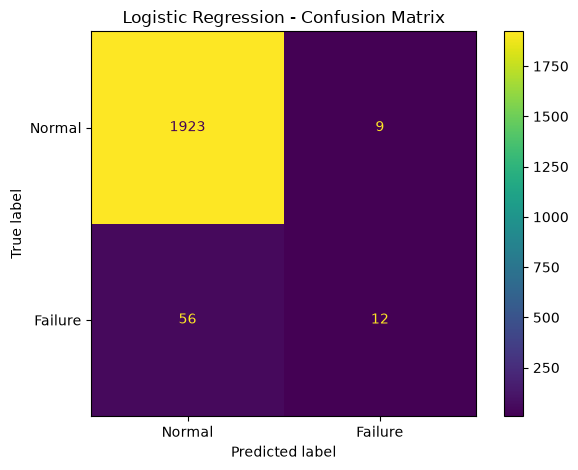

In [47]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Normal", "Failure"],
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

### Logistic Regression Baseline

The standard Logistic Regression model achieved strong ranking performance
(ROC-AUC = 0.9255), indicating that the available operating variables contain
substantial information for distinguishing failure from normal operation.

However, at the default 0.50 classification threshold, failure recall was only
17.65%. This means that most actual failures were not flagged by the model.

The result illustrates an important distinction between probability-ranking
performance and threshold-dependent classification performance. Because missed
failures can be important in predictive maintenance, class imbalance handling
and decision-threshold selection will be investigated next.

In [48]:
class_weight="balanced"

In [49]:
weighted_logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

weighted_logistic_pipeline.fit(X_train, y_train)

weighted_predictions = weighted_logistic_pipeline.predict(X_test)

weighted_probabilities = (
    weighted_logistic_pipeline.predict_proba(X_test)[:, 1]
)

In [50]:
weighted_accuracy = accuracy_score(
    y_test, weighted_predictions
)

weighted_precision = precision_score(
    y_test, weighted_predictions,
    zero_division=0
)

weighted_recall = recall_score(
    y_test, weighted_predictions,
    zero_division=0
)

weighted_f1 = f1_score(
    y_test, weighted_predictions,
    zero_division=0
)

weighted_roc_auc = roc_auc_score(
    y_test, weighted_probabilities
)

weighted_pr_auc = average_precision_score(
    y_test, weighted_probabilities
)

print(f"Accuracy : {weighted_accuracy:.4f}")
print(f"Precision: {weighted_precision:.4f}")
print(f"Recall   : {weighted_recall:.4f}")
print(f"F1 Score : {weighted_f1:.4f}")
print(f"ROC-AUC  : {weighted_roc_auc:.4f}")
print(f"PR-AUC   : {weighted_pr_auc:.4f}")

Accuracy : 0.8585
Precision: 0.1791
Recall   : 0.8824
F1 Score : 0.2978
ROC-AUC  : 0.9385
PR-AUC   : 0.4297


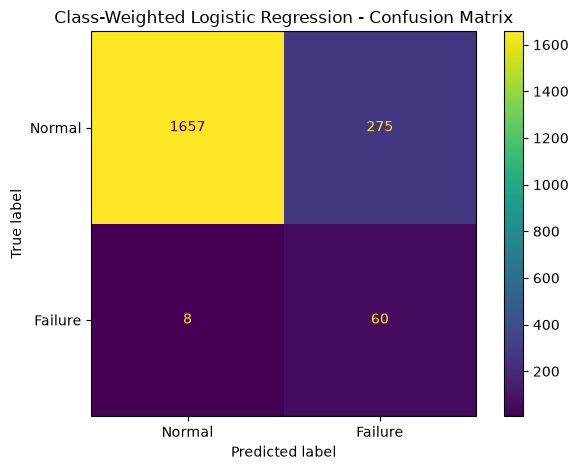

In [51]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    weighted_predictions,
    display_labels=["Normal", "Failure"],
    values_format="d"
)

plt.title(
    "Class-Weighted Logistic Regression - Confusion Matrix"
)
plt.tight_layout()
plt.show()

### Effect of Class Weighting

Applying balanced class weights substantially changed the behavior of Logistic Regression.

Failure recall increased from 17.65% to 88.24%, indicating that the weighted model detects a much larger proportion of actual machine failures. However, precision decreased from 57.14% to 17.91%, meaning that the increased sensitivity also produced substantially more false alarms.

The weighted model improved ROC-AUC from 0.9255 to 0.9385, while PR-AUC decreased from 0.4638 to 0.4297.

These results demonstrate that class-imbalance handling changes the operational trade-off between missed failures and false maintenance alarms. Therefore, model selection should not rely on accuracy or any single metric.

In [52]:
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1
0,0.10,0.331,0.691,0.448
1,0.15,0.417,0.588,0.488
2,0.20,0.472,0.500,0.486
3,0.25,0.500,0.426,0.460
4,0.30,0.565,0.382,0.456
5,0.35,0.581,0.265,0.364
6,0.40,0.593,0.235,0.337
7,0.45,0.542,0.191,0.283
8,0.50,0.571,0.176,0.270
9,0.55,0.611,0.162,0.256


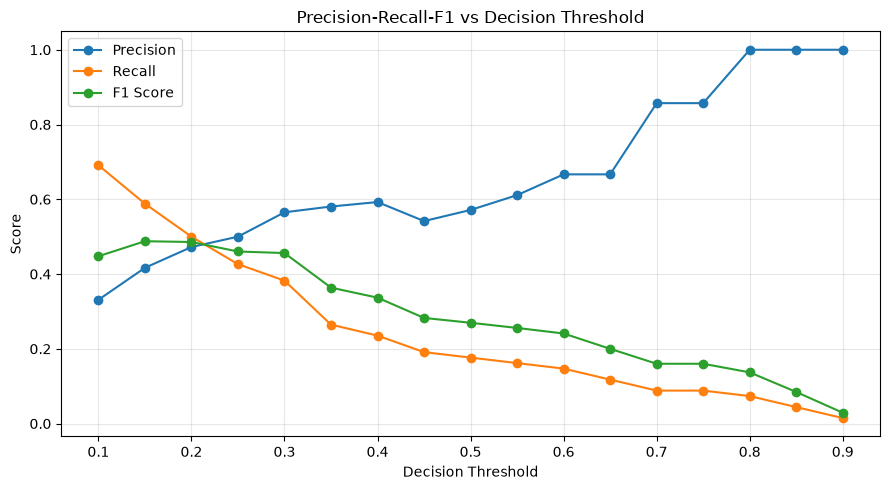

In [53]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "Precision-Recall-F1 vs Decision Threshold"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_f1_row

Threshold    0.150000
Precision    0.416667
Recall       0.588235
F1           0.487805
Name: 1, dtype: float64

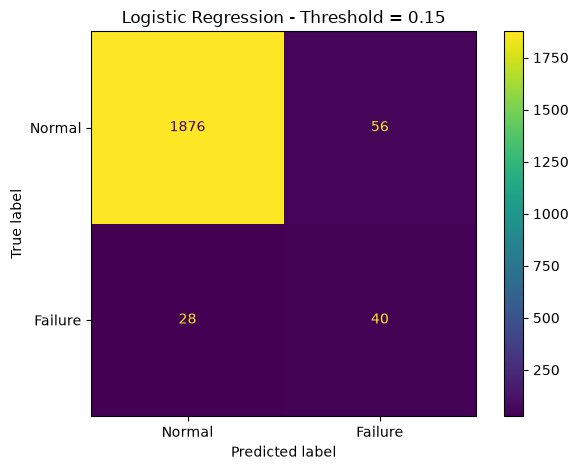

In [55]:
selected_threshold = 0.15

threshold_predictions = (
    logistic_probabilities >= selected_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    threshold_predictions,
    display_labels=["Normal", "Failure"],
    values_format="d"
)

plt.title(
    "Logistic Regression - Threshold = 0.15"
)
plt.tight_layout()
plt.show()

### Exploratory Threshold Analysis

The default 0.50 decision threshold resulted in high precision but poor failure recall.

During exploratory threshold analysis, a threshold near 0.15 produced the highest observed F1-score, increasing failure recall from 17.65% to 58.82% and F1-score from 26.97% to 48.78%.

This threshold is not treated as the final production threshold because it was identified using the held-out test set. Final threshold selection should be performed using validation data or cross-validation within the training dataset.

In [56]:
raw_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_raw = df[raw_features].copy()

X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [57]:
raw_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Type"]
        ),
        (
            "numerical",
            StandardScaler(),
            [
                "Air temperature [K]",
                "Process temperature [K]",
                "Rotational speed [rpm]",
                "Torque [Nm]",
                "Tool wear [min]"
            ]
        )
    ]
)

raw_logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", raw_preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

raw_logistic_pipeline.fit(
    X_raw_train,
    y_raw_train
)

raw_probabilities = raw_logistic_pipeline.predict_proba(
    X_raw_test
)[:, 1]

raw_predictions = raw_logistic_pipeline.predict(
    X_raw_test
)

In [58]:
print(
    "Raw Features ROC-AUC:",
    round(
        roc_auc_score(
            y_raw_test,
            raw_probabilities
        ),
        4
    )
)

print(
    "Raw Features PR-AUC:",
    round(
        average_precision_score(
            y_raw_test,
            raw_probabilities
        ),
        4
    )
)

print(
    "Raw Features F1:",
    round(
        f1_score(
            y_raw_test,
            raw_predictions
        ),
        4
    )
)

Raw Features ROC-AUC: 0.8994
Raw Features PR-AUC: 0.4205
Raw Features F1: 0.1772


### Impact of Physics-Informed Feature Engineering

A controlled ablation experiment was performed to evaluate whether the
physics-informed engineered features improved predictive performance.

The raw-feature Logistic Regression model achieved:

- ROC-AUC: 0.8994
- PR-AUC: 0.4205
- F1-score: 0.1772

After adding mechanical power, temperature difference, and the wear-load
interaction, performance increased to:

- ROC-AUC: 0.9255
- PR-AUC: 0.4638
- F1-score: 0.2697

The experiment indicates that the engineered features provide useful
predictive information to the linear model. In particular, the transformations
allow relationships involving speed, torque, temperature, and wear to be
represented more directly.

These results support retaining the engineered features for subsequent model
experiments. However, their usefulness will be reevaluated with nonlinear
models because such models may learn some of these interactions directly.

In [59]:
feature_names = (
    logistic_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    logistic_pipeline
    .named_steps["classifier"]
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

coefficient_df.round(4)

,Feature,Coefficient,Absolute Coefficient
6,numerical__Torque [Nm],5.1444,5.1444
8,numerical__Mechanical power [W],-2.3141,2.3141
5,numerical__Rotational speed [rpm],2.1692,2.1692
7,numerical__Tool wear [min],0.7974,0.7974
9,numerical__Temperature difference [K],-0.6317,0.6317
1,categorical__Type_L,0.3654,0.3654
3,numerical__Air temperature [K],0.2522,0.2522
0,categorical__Type_H,-0.2357,0.2357
2,categorical__Type_M,-0.1338,0.1338
4,numerical__Process temperature [K],-0.0866,0.0866


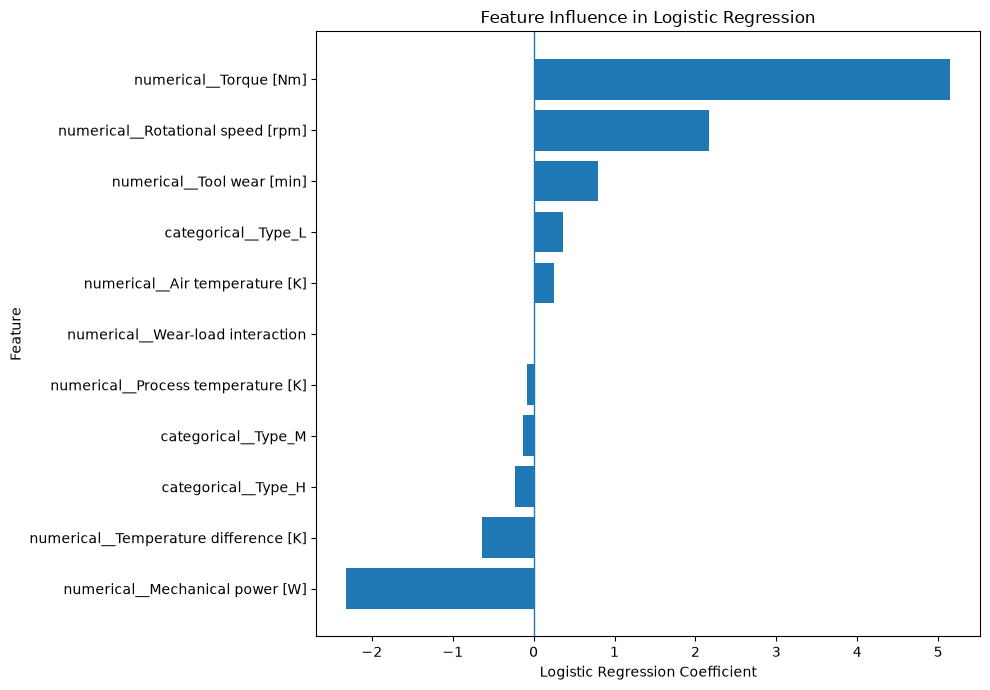

In [60]:
plot_df = coefficient_df.sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title(
    "Feature Influence in Logistic Regression"
)

plt.tight_layout()
plt.show()

In [61]:
multicollinearity_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
    "Temperature difference [K]",
    "Wear-load interaction"
]

feature_corr = df[
    multicollinearity_features
].corr()

feature_corr.round(3)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical power [W],Temperature difference [K],Wear-load interaction
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,-0.011,-0.700,0.007
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,-0.011,-0.268,0.006
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.806,-0.017,-0.331
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.979,0.007,0.377
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,-0.003,-0.008,0.898
Mechanical power [W],-0.011,-0.011,-0.806,0.979,-0.003,1.000,0.007,0.369
Temperature difference [K],-0.700,-0.268,-0.017,0.007,-0.008,0.007,1.000,-0.005
Wear-load interaction,0.007,0.006,-0.331,0.377,0.898,0.369,-0.005,1.000


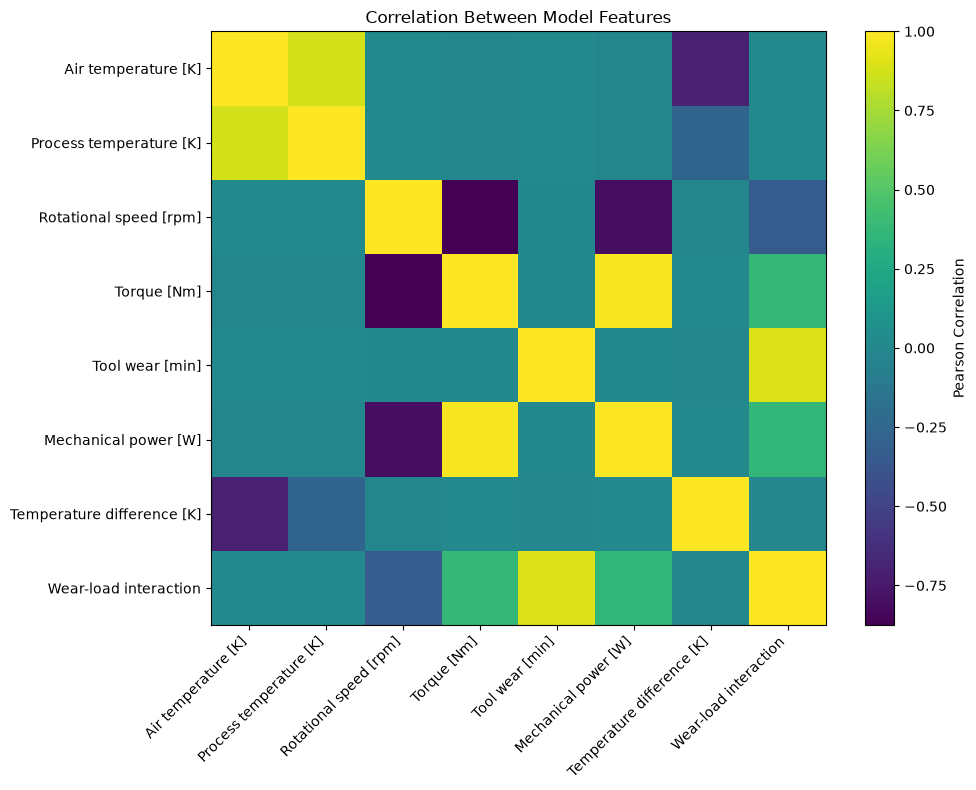

In [62]:
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    feature_corr,
    aspect="auto"
)

ax.set_xticks(
    range(len(multicollinearity_features))
)
ax.set_yticks(
    range(len(multicollinearity_features))
)

ax.set_xticklabels(
    multicollinearity_features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    multicollinearity_features
)

plt.colorbar(
    im,
    ax=ax,
    label="Pearson Correlation"
)

plt.title(
    "Correlation Between Model Features"
)

plt.tight_layout()
plt.show()

### Logistic Regression Coefficient Interpretation

The fitted Logistic Regression model assigns its largest positive coefficient
to torque. Tool wear also contributes positively to predicted failure risk,
while temperature difference has a negative coefficient.

Individual coefficients must be interpreted cautiously because several
predictors are mathematically related. Mechanical power is derived from torque
and rotational speed, while the wear-load feature is derived from torque and
tool wear. These relationships introduce multicollinearity and interaction
effects.

Consequently, coefficient signs represent conditional relationships within
the fitted multivariable model and should not be interpreted as direct
physical causation.

The near-zero wear-load coefficient does not imply that the feature contains
no predictive information. Its information may overlap with torque and tool
wear already present in the model. Feature-ablation experiments will therefore
be used to quantify the incremental predictive value of each engineered
feature.

### Multicollinearity Analysis

The feature-correlation analysis reveals strong relationships among several
predictors.

Mechanical power is strongly related to torque and rotational speed because
it is physically derived from these variables. Similarly, the wear-load
interaction is strongly related to tool wear and torque by construction.

These relationships explain why individual Logistic Regression coefficients
must be interpreted cautiously. Correlated predictors can redistribute
coefficient magnitude and may even change coefficient signs.

Rather than removing engineered features solely because of correlation,
controlled ablation experiments are used to determine whether each engineered
feature provides incremental predictive value.

In [63]:
def evaluate_feature_set(feature_list, model_name):

    X_exp = df[feature_list].copy()

    X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
        X_exp,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    categorical = ["Type"]

    numerical = [
        feature for feature in feature_list
        if feature != "Type"
    ]

    experiment_preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            ),
            (
                "numerical",
                StandardScaler(),
                numerical
            )
        ]
    )

    experiment_pipeline = Pipeline(
        steps=[
            ("preprocessor", experiment_preprocessor),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    )

    experiment_pipeline.fit(
        X_train_exp,
        y_train_exp
    )

    predictions = experiment_pipeline.predict(
        X_test_exp
    )

    probabilities = experiment_pipeline.predict_proba(
        X_test_exp
    )[:, 1]

    return {
        "Model": model_name,
        "Number of Features": len(feature_list),
        "ROC-AUC": roc_auc_score(
            y_test_exp,
            probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test_exp,
            probabilities
        ),
        "F1": f1_score(
            y_test_exp,
            predictions,
            zero_division=0
        )
    }

In [64]:
raw_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

feature_experiments = {
    "Raw only":
        raw_features,

    "Raw + Mechanical Power":
        raw_features + [
            "Mechanical power [W]"
        ],

    "Raw + Temperature Difference":
        raw_features + [
            "Temperature difference [K]"
        ],

    "Raw + Wear-Load":
        raw_features + [
            "Wear-load interaction"
        ],

    "Raw + All Engineered":
        raw_features + [
            "Mechanical power [W]",
            "Temperature difference [K]",
            "Wear-load interaction"
        ]
}

In [65]:
ablation_results = []

for model_name, features in feature_experiments.items():

    result = evaluate_feature_set(
        features,
        model_name
    )

    ablation_results.append(result)

ablation_df = pd.DataFrame(
    ablation_results
)

ablation_df.round(4)

,Model,Number of Features,ROC-AUC,PR-AUC,F1
0,Raw only,6,0.8994,0.4205,0.1772
1,Raw + Mechanical Power,7,0.9253,0.4619,0.2697
2,Raw + Temperature Difference,7,0.9002,0.4213,0.1750
3,Raw + Wear-Load,7,0.8986,0.4197,0.1772
4,Raw + All Engineered,9,0.9255,0.4638,0.2697


### Feature Ablation Study

A controlled ablation study was conducted to measure the incremental predictive
value of each physics-informed engineered feature.

The raw Logistic Regression model achieved ROC-AUC = 0.8994, PR-AUC = 0.4205,
and F1 = 0.1772.

Adding mechanical power improved performance to ROC-AUC = 0.9253,
PR-AUC = 0.4619, and F1 = 0.2697. In contrast, temperature difference and
wear-load interaction produced little or no improvement when added
individually.

Using all three engineered features produced only a marginal improvement over
mechanical power alone.

Mechanical power therefore appears to account for most of the predictive gain
from the current physics-informed feature engineering. This is physically
meaningful because mechanical power introduces an interaction between torque
and rotational speed that a linear Logistic Regression model cannot directly
represent from the two raw variables alone.

These results are exploratory because feature selection was examined using the
current held-out split. Final feature selection will be validated using
stratified cross-validation on the training data.


In [66]:
lean_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]"
]

X_lean = df[lean_features].copy()

X_lean_train, X_lean_test, y_lean_train, y_lean_test = train_test_split(
    X_lean,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_lean_train.shape)
print("Test:", X_lean_test.shape)

Training: (8000, 7)
Test: (2000, 7)


In [67]:
lean_categorical_features = [
    "Type"
]

lean_numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]"
]

lean_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            lean_categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            lean_numerical_features
        )
    ]
)

In [68]:
standard_lr_cv = Pipeline(
    steps=[
        ("preprocessor", lean_preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

weighted_lr_cv = Pipeline(
    steps=[
        ("preprocessor", lean_preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [69]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [70]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [71]:
standard_cv_results = cross_validate(
    standard_lr_cv,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

weighted_cv_results = cross_validate(
    weighted_lr_cv,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [72]:
cv_summary = pd.DataFrame({
    "Model": [
        "Standard Logistic Regression",
        "Balanced Logistic Regression"
    ],

    "Precision Mean": [
        standard_cv_results["test_precision"].mean(),
        weighted_cv_results["test_precision"].mean()
    ],

    "Recall Mean": [
        standard_cv_results["test_recall"].mean(),
        weighted_cv_results["test_recall"].mean()
    ],

    "F1 Mean": [
        standard_cv_results["test_f1"].mean(),
        weighted_cv_results["test_f1"].mean()
    ],

    "ROC-AUC Mean": [
        standard_cv_results["test_roc_auc"].mean(),
        weighted_cv_results["test_roc_auc"].mean()
    ],

    "PR-AUC Mean": [
        standard_cv_results["test_pr_auc"].mean(),
        weighted_cv_results["test_pr_auc"].mean()
    ]
})

cv_summary.round(4)

,Model,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean
0,Standard Logistic Regression,0.7694,0.2399,0.3646,0.9150,0.5008
1,Balanced Logistic Regression,0.1650,0.8231,0.2747,0.9196,0.4836


In [73]:
cv_stability = pd.DataFrame({
    "Model": [
        "Standard Logistic Regression",
        "Balanced Logistic Regression"
    ],

    "F1 Mean": [
        standard_cv_results["test_f1"].mean(),
        weighted_cv_results["test_f1"].mean()
    ],

    "F1 Std": [
        standard_cv_results["test_f1"].std(),
        weighted_cv_results["test_f1"].std()
    ],

    "ROC-AUC Mean": [
        standard_cv_results["test_roc_auc"].mean(),
        weighted_cv_results["test_roc_auc"].mean()
    ],

    "ROC-AUC Std": [
        standard_cv_results["test_roc_auc"].std(),
        weighted_cv_results["test_roc_auc"].std()
    ],

    "PR-AUC Mean": [
        standard_cv_results["test_pr_auc"].mean(),
        weighted_cv_results["test_pr_auc"].mean()
    ],

    "PR-AUC Std": [
        standard_cv_results["test_pr_auc"].std(),
        weighted_cv_results["test_pr_auc"].std()
    ]
})

cv_stability.round(4)

,Model,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std
0,Standard Logistic Regression,0.3646,0.0406,0.9150,0.0153,0.5008,0.0311
1,Balanced Logistic Regression,0.2747,0.0181,0.9196,0.0122,0.4836,0.0256


## 8. Stratified Cross-Validation

To reduce dependence on a single train-validation split, model development is
performed using 5-fold stratified cross-validation on the training dataset.

Stratification preserves the minority failure proportion within each fold.

All preprocessing operations, including numerical scaling and categorical
encoding, are contained inside the scikit-learn Pipeline. Therefore, each
cross-validation fold fits its preprocessing transformations using only the
corresponding training portion of that fold.

The held-out test dataset is excluded from cross-validation and will be
reserved for final model evaluation.

Precision, recall, F1-score, ROC-AUC, and PR-AUC are evaluated because the
failure class is highly imbalanced.

### Cross-Validation Results

Five-fold stratified cross-validation confirmed a substantial precision-recall
trade-off between the two Logistic Regression configurations.

The standard model achieved higher precision (0.7694), F1-score (0.3646),
and PR-AUC (0.5008), but detected only 23.99% of failures on average.

The balanced model increased average failure recall to 82.31%, but precision
decreased to 16.50%. Its ROC-AUC was slightly higher, while PR-AUC was
slightly lower than the standard model.

Cross-validation variability was relatively small for both models, suggesting
that the observed behavior is reasonably consistent across folds.

These results indicate that class weighting changes the operating behavior of
the classifier rather than universally improving every performance metric.
The appropriate configuration depends on the operational costs associated
with missed failures and false maintenance alarms.

In [74]:
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    standard_lr_cv,
    X_lean_train,
    y_lean_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions:", len(oof_probabilities))
print("Training observations:", len(y_lean_train))

OOF predictions: 8000
Training observations: 8000


In [75]:
threshold_results_cv = []

for threshold in np.arange(0.05, 0.51, 0.01):

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results_cv.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_lean_train,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_lean_train,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_lean_train,
            predictions,
            zero_division=0
        )
    })

threshold_cv_df = pd.DataFrame(
    threshold_results_cv
)

threshold_cv_df.round(3)

,Threshold,Precision,Recall,F1
0,0.05,0.193,0.790,0.310
1,0.06,0.217,0.756,0.337
2,0.07,0.237,0.720,0.356
3,0.08,0.255,0.697,0.374
4,0.09,0.272,0.683,0.389
5,0.10,0.290,0.657,0.402
6,0.11,0.312,0.646,0.421
7,0.12,0.337,0.631,0.440
8,0.13,0.348,0.601,0.441
9,0.14,0.368,0.583,0.451


In [76]:
best_threshold_row = threshold_cv_df.loc[
    threshold_cv_df["F1"].idxmax()
]

best_threshold_row

Threshold    0.200000
Precision    0.484536
Recall       0.520295
F1           0.501779
Name: 15, dtype: float64

In [77]:
high_recall_candidates = threshold_cv_df[
    threshold_cv_df["Recall"] >= 0.80
]

best_high_recall = (
    high_recall_candidates
    .sort_values(
        ["Precision", "F1"],
        ascending=False
    )
    .head(10)
)

best_high_recall.round(3)

,Threshold,Precision,Recall,F1


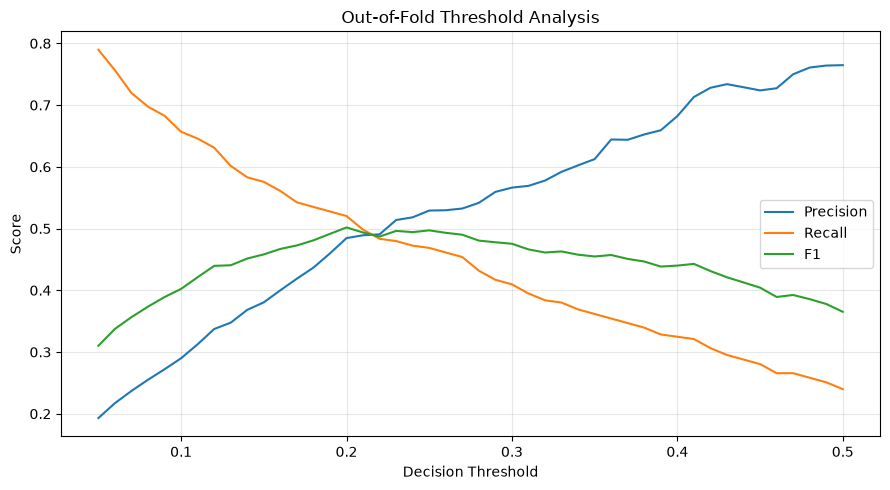

In [78]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_cv_df["Threshold"],
    threshold_cv_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_cv_df["Threshold"],
    threshold_cv_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_cv_df["Threshold"],
    threshold_cv_df["F1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title(
    "Out-of-Fold Threshold Analysis"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [79]:
print("Maximum recall:", threshold_cv_df["Recall"].max())

print(
    "Threshold with maximum recall:",
    threshold_cv_df.loc[
        threshold_cv_df["Recall"].idxmax(),
        "Threshold"
    ]
)

print(
    "Number of candidates with recall >= 0.80:",
    len(high_recall_candidates)
)

Maximum recall: 0.7896678966789668
Threshold with maximum recall: 0.05
Number of candidates with recall >= 0.80: 0


In [80]:
extended_threshold_results = []

for threshold in np.arange(0.01, 0.051, 0.005):

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    extended_threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_lean_train,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_lean_train,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_lean_train,
            predictions,
            zero_division=0
        )
    })

extended_threshold_df = pd.DataFrame(
    extended_threshold_results
)

extended_threshold_df.round(3)

,Threshold,Precision,Recall,F1
0,0.010,0.078,0.930,0.143
1,0.015,0.097,0.919,0.175
2,0.020,0.112,0.889,0.199
3,0.025,0.129,0.863,0.224
4,0.030,0.141,0.838,0.242
5,0.035,0.154,0.815,0.259
6,0.040,0.166,0.808,0.276
7,0.045,0.180,0.797,0.294
8,0.050,0.193,0.790,0.310


In [81]:
high_recall_candidates = (
    extended_threshold_df[
        extended_threshold_df["Recall"] >= 0.80
    ]
    .sort_values(
        ["Precision", "F1"],
        ascending=False
    )
)

high_recall_candidates.round(3)

,Threshold,Precision,Recall,F1
6,0.040,0.166,0.808,0.276
5,0.035,0.154,0.815,0.259
4,0.030,0.141,0.838,0.242
3,0.025,0.129,0.863,0.224
2,0.020,0.112,0.889,0.199
1,0.015,0.097,0.919,0.175
0,0.010,0.078,0.930,0.143


In [82]:
from sklearn.metrics import confusion_matrix

cost_results = []

COST_FALSE_NEGATIVE = 10000
COST_FALSE_POSITIVE = 500

for threshold in np.arange(0.01, 0.51, 0.01):

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_lean_train,
        predictions
    ).ravel()

    total_cost = (
        fn * COST_FALSE_NEGATIVE
        + fp * COST_FALSE_POSITIVE
    )

    cost_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "Total Cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)

In [83]:
best_cost_row = cost_df.loc[
    cost_df["Total Cost"].idxmin()
]

best_cost_row

Threshold           0.05
TP                214.00
FP                895.00
TN               6834.00
FN                 57.00
Total Cost    1017500.00
Name: 4, dtype: float64

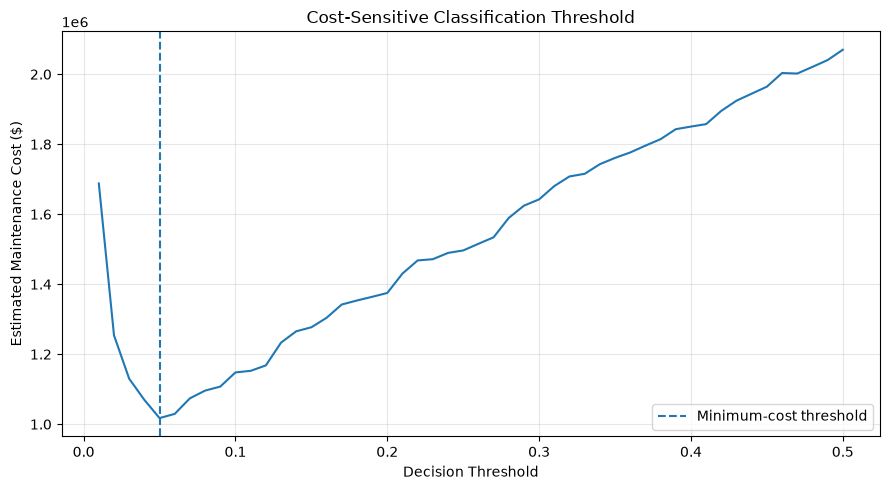

In [84]:
plt.figure(figsize=(9, 5))

plt.plot(
    cost_df["Threshold"],
    cost_df["Total Cost"]
)

plt.axvline(
    best_cost_row["Threshold"],
    linestyle="--",
    label="Minimum-cost threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Estimated Maintenance Cost ($)")
plt.title(
    "Cost-Sensitive Classification Threshold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Cost-Sensitive Threshold Selection

Classification thresholds were also evaluated using an illustrative maintenance
cost model.

A missed machine failure (false negative) was assigned a cost of $10,000,
while an unnecessary maintenance alert (false positive) was assigned a cost
of $500. These values are hypothetical and are used to demonstrate
cost-sensitive decision making rather than represent actual AI4I operating
costs.

For each threshold, total estimated cost was calculated as:

Total Cost = (False Negatives × $10,000) + (False Positives × $500)

Using out-of-fold predictions from the training data, the minimum-cost
threshold among the evaluated candidates was 0.05.

At this threshold:

- True Positives: 214
- False Positives: 895
- True Negatives: 6,834
- False Negatives: 57
- Estimated Cost: $1,017,500

The relatively low threshold reflects the assumed asymmetric consequences:
missing a machine failure is substantially more expensive than generating an
unnecessary maintenance alert.

The selected threshold therefore depends not only on statistical model
performance but also on the operational cost structure.

In [85]:
cost_threshold = float(
    best_cost_row["Threshold"]
)

cost_predictions = (
    oof_probabilities >= cost_threshold
).astype(int)

cost_threshold_metrics = pd.Series({
    "Threshold": cost_threshold,

    "Precision": precision_score(
        y_lean_train,
        cost_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_lean_train,
        cost_predictions,
        zero_division=0
    ),

    "F1": f1_score(
        y_lean_train,
        cost_predictions,
        zero_division=0
    )
})

cost_threshold_metrics.round(4)

Threshold    0.0500
Precision    0.1930
Recall       0.7897
F1           0.3101
dtype: float64

In [86]:
from sklearn.ensemble import RandomForestClassifier

random_forest_cv = Pipeline(
    steps=[
        ("preprocessor", lean_preprocessor),

        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [87]:
rf_cv_results = cross_validate(
    random_forest_cv,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [88]:
rf_summary = pd.Series({
    "Precision Mean":
        rf_cv_results["test_precision"].mean(),

    "Recall Mean":
        rf_cv_results["test_recall"].mean(),

    "F1 Mean":
        rf_cv_results["test_f1"].mean(),

    "ROC-AUC Mean":
        rf_cv_results["test_roc_auc"].mean(),

    "PR-AUC Mean":
        rf_cv_results["test_pr_auc"].mean(),

    "F1 Std":
        rf_cv_results["test_f1"].std(),

    "ROC-AUC Std":
        rf_cv_results["test_roc_auc"].std(),

    "PR-AUC Std":
        rf_cv_results["test_pr_auc"].std()
})

rf_summary.round(4)

Precision Mean    0.8043
Recall Mean       0.7308
F1 Mean           0.7639
ROC-AUC Mean      0.9750
PR-AUC Mean       0.8270
F1 Std            0.0231
ROC-AUC Std       0.0135
PR-AUC Std        0.0298
dtype: float64

In [89]:
rf_summary.round(4)

Precision Mean    0.8043
Recall Mean       0.7308
F1 Mean           0.7639
ROC-AUC Mean      0.9750
PR-AUC Mean       0.8270
F1 Std            0.0231
ROC-AUC Std       0.0135
PR-AUC Std        0.0298
dtype: float64

### Random Forest Baseline

The nonlinear Random Forest classifier substantially outperformed both
Logistic Regression baselines during five-fold stratified cross-validation.

The Random Forest achieved:

- Precision: 0.8043
- Recall: 0.7308
- F1-score: 0.7639
- ROC-AUC: 0.9750
- PR-AUC: 0.8270

The improvement is particularly important for the minority failure class.
Unlike Logistic Regression, which exhibited a strong precision-recall
trade-off, Random Forest achieved relatively high precision and recall
simultaneously.

This suggests that machine failure is governed by nonlinear relationships,
threshold effects, and interactions among operating variables that cannot be
fully represented by a linear decision boundary.

The relatively low cross-validation standard deviations also indicate that
the model's performance is reasonably stable across folds.

These results establish Random Forest as a strong nonlinear candidate for
further model development. The held-out test set remains excluded from model
selection.

In [90]:
raw_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_raw = df[raw_features].copy()

X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [91]:
raw_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Type"]
        ),
        (
            "numerical",
            StandardScaler(),
            [
                "Air temperature [K]",
                "Process temperature [K]",
                "Rotational speed [rpm]",
                "Torque [Nm]",
                "Tool wear [min]"
            ]
        )
    ]
)

In [92]:
rf_raw_pipeline = Pipeline(
    steps=[
        ("preprocessor", raw_preprocessor),

        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [93]:
rf_raw_cv_results = cross_validate(
    rf_raw_pipeline,
    X_raw_train,
    y_raw_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [94]:
rf_feature_comparison = pd.DataFrame({
    "Model": [
        "Random Forest - Raw",
        "Random Forest - Raw + Mechanical Power"
    ],

    "Precision": [
        rf_raw_cv_results["test_precision"].mean(),
        rf_cv_results["test_precision"].mean()
    ],

    "Recall": [
        rf_raw_cv_results["test_recall"].mean(),
        rf_cv_results["test_recall"].mean()
    ],

    "F1": [
        rf_raw_cv_results["test_f1"].mean(),
        rf_cv_results["test_f1"].mean()
    ],

    "ROC-AUC": [
        rf_raw_cv_results["test_roc_auc"].mean(),
        rf_cv_results["test_roc_auc"].mean()
    ],

    "PR-AUC": [
        rf_raw_cv_results["test_pr_auc"].mean(),
        rf_cv_results["test_pr_auc"].mean()
    ]
})

rf_feature_comparison.round(4)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest - Raw,0.7009,0.6201,0.6575,0.9693,0.7339
1,Random Forest - Raw + Mechanical Power,0.8043,0.7308,0.7639,0.9750,0.8270


### Effect of Physics-Informed Feature Engineering on Random Forest

A controlled experiment was performed to determine whether the engineered
mechanical-power feature remains useful for a nonlinear Random Forest model.

Using only the raw operating variables, Random Forest achieved an average
F1-score of 0.6575 and PR-AUC of 0.7339.

After adding mechanical power, performance increased to an F1-score of
0.7639 and PR-AUC of 0.8270. Precision increased from 0.7009 to 0.8043,
while recall increased from 0.6201 to 0.7308.

Although Random Forest can learn nonlinear interactions between torque and
rotational speed through recursive tree splits, explicitly supplying the
physics-informed mechanical-power relationship improved predictive
performance.

This experiment demonstrates that engineering domain knowledge can complement
nonlinear machine-learning models rather than merely compensate for the
limitations of linear models.

In [95]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_distributions = {
    "classifier__n_estimators": [
        200, 300, 500, 700
    ],

    "classifier__max_depth": [
        None, 5, 10, 15, 20
    ],

    "classifier__min_samples_split": [
        2, 5, 10, 20
    ],

    "classifier__min_samples_leaf": [
        1, 2, 4, 8
    ],

    "classifier__max_features": [
        "sqrt", "log2", None
    ]
}

In [96]:
rf_random_search = RandomizedSearchCV(
    estimator=random_forest_cv,
    param_distributions=rf_param_distributions,

    n_iter=30,

    scoring="average_precision",

    cv=cv,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=True
)

rf_random_search.fit(
    X_lean_train,
    y_lean_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set

In [97]:
print("Best parameters:")
print(rf_random_search.best_params_)

print(
    "\nBest CV PR-AUC:",
    round(
        rf_random_search.best_score_,
        4
    )
)

Best parameters:
{'classifier__n_estimators': 700, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': None}

Best CV PR-AUC: 0.8298


In [98]:
best_rf = rf_random_search.best_estimator_

best_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Type','Air temperature [K]','Process temperature [K]',...,'Torque [Nm]', 'Tool wear [min]','Mechanical power [W]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default 

### Random Forest Hyperparameter Optimization

RandomizedSearchCV was used to optimize the Random Forest using five-fold
stratified cross-validation. Average precision (PR-AUC) was selected as the
optimization objective because machine failures represent a small minority
of observations.

The best configuration used:

- 700 trees
- unlimited tree depth
- minimum samples split = 2
- minimum samples leaf = 1
- log2 feature sampling

The optimized cross-validation PR-AUC was 0.8298, compared with 0.8270 for
the baseline Random Forest.

The relatively small improvement indicates that the baseline Random Forest
was already well suited to the dataset. Hyperparameter optimization therefore
provided incremental rather than transformational improvement.

Because the selected configuration permits fully grown trees, additional
analysis is required to assess potential overfitting before selecting the
final model.

In [99]:
tuned_rf_cv_results = cross_validate(
    best_rf,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

In [100]:
tuned_rf_summary = pd.Series({
    "Precision Mean":
        tuned_rf_cv_results["test_precision"].mean(),

    "Recall Mean":
        tuned_rf_cv_results["test_recall"].mean(),

    "F1 Mean":
        tuned_rf_cv_results["test_f1"].mean(),

    "ROC-AUC Mean":
        tuned_rf_cv_results["test_roc_auc"].mean(),

    "PR-AUC Mean":
        tuned_rf_cv_results["test_pr_auc"].mean(),

    "F1 Std":
        tuned_rf_cv_results["test_f1"].std(),

    "ROC-AUC Std":
        tuned_rf_cv_results["test_roc_auc"].std(),

    "PR-AUC Std":
        tuned_rf_cv_results["test_pr_auc"].std()
})

tuned_rf_summary.round(4)

Precision Mean    0.8219
Recall Mean       0.7345
F1 Mean           0.7739
ROC-AUC Mean      0.9755
PR-AUC Mean       0.8298
F1 Std            0.0241
ROC-AUC Std       0.0140
PR-AUC Std        0.0303
dtype: float64

In [101]:
overfitting_check = pd.DataFrame({
    "Metric": [
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Train": [
        tuned_rf_cv_results["train_f1"].mean(),
        tuned_rf_cv_results["train_roc_auc"].mean(),
        tuned_rf_cv_results["train_pr_auc"].mean()
    ],

    "Validation": [
        tuned_rf_cv_results["test_f1"].mean(),
        tuned_rf_cv_results["test_roc_auc"].mean(),
        tuned_rf_cv_results["test_pr_auc"].mean()
    ]
})

overfitting_check["Gap"] = (
    overfitting_check["Train"]
    - overfitting_check["Validation"]
)

overfitting_check.round(4)

,Metric,Train,Validation,Gap
0,F1,0.9995,0.7739,0.2256
1,ROC-AUC,1.0000,0.9755,0.0245
2,PR-AUC,1.0000,0.8298,0.1702


In [102]:
regularized_rf_params = {
    "classifier__n_estimators": [
        300, 500, 700
    ],

    "classifier__max_depth": [
        5, 8, 10, 12, 15
    ],

    "classifier__min_samples_split": [
        5, 10, 20
    ],

    "classifier__min_samples_leaf": [
        2, 4, 8, 12
    ],

    "classifier__max_features": [
        "sqrt", "log2"
    ]
}


In [103]:
regularized_rf_search = RandomizedSearchCV(
    estimator=random_forest_cv,

    param_distributions=regularized_rf_params,

    n_iter=30,

    scoring="average_precision",

    cv=cv,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=True
)

regularized_rf_search.fit(
    X_lean_train,
    y_lean_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [5, 8, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [2, 4, ...], 'classifier__min_samples_split': [5, 10, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be

In [104]:
print("Best regularized parameters:")
print(
    regularized_rf_search.best_params_
)

print(
    "\nBest regularized CV PR-AUC:",
    round(
        regularized_rf_search.best_score_,
        4
    )
)

Best regularized parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 15}

Best regularized CV PR-AUC: 0.819


In [105]:
regularized_rf = (
    regularized_rf_search.best_estimator_
)

regularized_cv_results = cross_validate(
    regularized_rf,
    X_lean_train,
    y_lean_train,

    cv=cv,
    scoring=scoring,

    n_jobs=-1,
    return_train_score=True
)

In [106]:
regularized_summary = pd.Series({
    "Precision Mean":
        regularized_cv_results["test_precision"].mean(),

    "Recall Mean":
        regularized_cv_results["test_recall"].mean(),

    "F1 Mean":
        regularized_cv_results["test_f1"].mean(),

    "ROC-AUC Mean":
        regularized_cv_results["test_roc_auc"].mean(),

    "PR-AUC Mean":
        regularized_cv_results["test_pr_auc"].mean(),

    "F1 Std":
        regularized_cv_results["test_f1"].std(),

    "ROC-AUC Std":
        regularized_cv_results["test_roc_auc"].std(),

    "PR-AUC Std":
        regularized_cv_results["test_pr_auc"].std()
})

regularized_summary.round(4)

Precision Mean    0.6402
Recall Mean       0.8007
F1 Mean           0.7114
ROC-AUC Mean      0.9760
PR-AUC Mean       0.8190
F1 Std            0.0380
ROC-AUC Std       0.0131
PR-AUC Std        0.0304
dtype: float64

In [107]:
regularized_overfitting = pd.DataFrame({
    "Metric": [
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Train": [
        regularized_cv_results["train_f1"].mean(),
        regularized_cv_results["train_roc_auc"].mean(),
        regularized_cv_results["train_pr_auc"].mean()
    ],

    "Validation": [
        regularized_cv_results["test_f1"].mean(),
        regularized_cv_results["test_roc_auc"].mean(),
        regularized_cv_results["test_pr_auc"].mean()
    ]
})

regularized_overfitting["Gap"] = (
    regularized_overfitting["Train"]
    - regularized_overfitting["Validation"]
)

regularized_overfitting.round(4)

,Metric,Train,Validation,Gap
0,F1,0.9057,0.7114,0.1943
1,ROC-AUC,1.0000,0.9760,0.0240
2,PR-AUC,1.0000,0.8190,0.1810


### Overfitting Assessment

The optimized Random Forest achieved strong validation performance but nearly
perfect training performance. Training F1 reached 0.9995 and training PR-AUC
reached 1.0000, compared with validation F1 of 0.7739 and PR-AUC of 0.8298.

This train-validation gap indicates that the unrestricted trees have enough
capacity to nearly memorize their training folds.

A second hyperparameter search therefore constrains tree depth and minimum
node sizes. The objective is not simply to maximize validation PR-AUC, but to
identify a model that provides a stronger balance between predictive
performance and generalization.

### Regularization Experiment and Candidate Selection

A second Random Forest search constrained tree depth and minimum node sizes
to investigate whether stronger regularization would reduce the observed
train-validation performance gap.

The regularized model increased cross-validation recall from 0.7345 to
0.8007. However, precision decreased from 0.8219 to 0.6402, F1 decreased
from 0.7739 to 0.7114, and PR-AUC decreased from 0.8298 to 0.8190.

Regularization reduced the F1 train-validation gap from 0.2256 to 0.1943,
but did not eliminate the generalization gap. The PR-AUC gap did not improve.

For the PR-AUC-centered model-development objective used in this project,
the tuned Random Forest is therefore retained as the primary candidate.
The regularized model remains relevant when higher failure recall is an
explicit operational requirement.

No further hyperparameter selection is performed using the held-out test
dataset.

In [108]:
final_rf = best_rf

final_test_predictions = final_rf.predict(
    X_lean_test
)

final_test_probabilities = final_rf.predict_proba(
    X_lean_test
)[:, 1]

In [109]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

final_test_metrics = pd.Series({
    "Accuracy": accuracy_score(
        y_lean_test,
        final_test_predictions
    ),

    "Precision": precision_score(
        y_lean_test,
        final_test_predictions,
        zero_division=0
    ),

    "Recall": recall_score(
        y_lean_test,
        final_test_predictions,
        zero_division=0
    ),

    "F1": f1_score(
        y_lean_test,
        final_test_predictions,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_lean_test,
        final_test_probabilities
    ),

    "PR-AUC": average_precision_score(
        y_lean_test,
        final_test_probabilities
    )
})

final_test_metrics.round(4)

Accuracy     0.9845
Precision    0.8364
Recall       0.6765
F1           0.7480
ROC-AUC      0.9639
PR-AUC       0.7903
dtype: float64

In [110]:
final_confusion_matrix = confusion_matrix(
    y_lean_test,
    final_test_predictions
)

final_confusion_matrix

array([[1923,    9],
       [  22,   46]])

In [111]:
final_test_metrics.round(4)

Accuracy     0.9845
Precision    0.8364
Recall       0.6765
F1           0.7480
ROC-AUC      0.9639
PR-AUC       0.7903
dtype: float64

In [112]:
from pathlib import Path

FIGURES_DIR = Path("../reports/figures")

# Create reports/figures if it doesn't already exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURES_DIR.resolve())
print("Exists:", FIGURES_DIR.exists())

Figure directory: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures
Exists: True


In [113]:
output_path = FIGURES_DIR / "final_confusion_matrix.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved to:")
print(output_path.resolve())

Saved to:
C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\final_confusion_matrix.png


<Figure size 640x480 with 0 Axes>

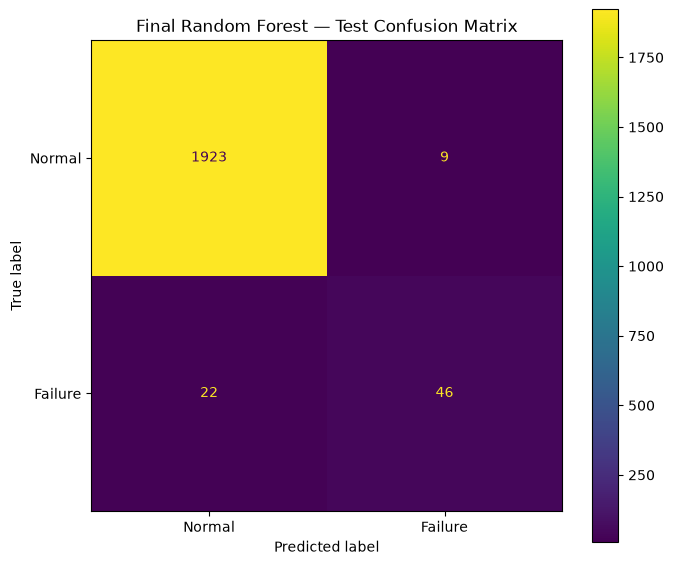

Saved successfully: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\final_confusion_matrix.png


In [114]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create output directory
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=["Normal", "Failure"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Final Random Forest — Test Confusion Matrix"
)

plt.tight_layout()

# Save before displaying
output_path = FIGURES_DIR / "final_confusion_matrix.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved successfully: {output_path.resolve()}")

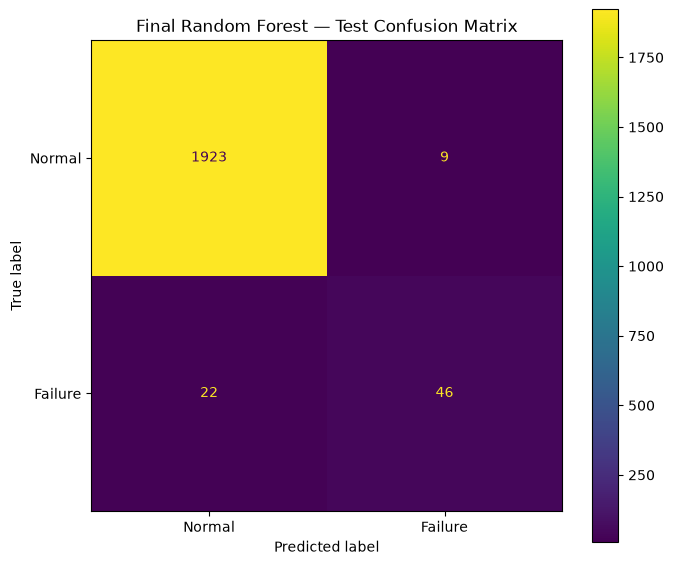

Saved successfully:
C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\final_confusion_matrix.png
File exists: True


In [115]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Create the figures directory if it does not exist
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 2. Define the output filename
output_path = FIGURES_DIR / "final_confusion_matrix.png"

# 3. Create confusion matrix figure
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=["Normal", "Failure"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Final Random Forest — Test Confusion Matrix")

plt.tight_layout()

# 4. Save the figure
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

# 5. Display it
plt.show()

# 6. Confirm save location
print("Saved successfully:")
print(output_path.resolve())
print("File exists:", output_path.exists())

In [116]:
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

In [117]:
final_test_metrics.round(4)

Accuracy     0.9845
Precision    0.8364
Recall       0.6765
F1           0.7480
ROC-AUC      0.9639
PR-AUC       0.7903
dtype: float64

### Final Model Performance

The selected Random Forest was evaluated once on the held-out test set after
model development and hyperparameter selection.

| Metric | Test Performance |
|---|---:|
| Accuracy | 0.9845 |
| Precision | 0.8364 |
| Recall | 0.6765 |
| F1-score | 0.7480 |
| ROC-AUC | 0.9639 |
| PR-AUC | 0.7903 |

The model correctly identified 46 of 68 machine failures while generating
only 9 false-positive maintenance alerts.

Although accuracy reached 98.45%, accuracy is not the primary metric because
machine failures represent only approximately 3.4% of the dataset. PR-AUC,
recall, precision, and F1-score provide more meaningful measures of
minority-class performance.

The held-out PR-AUC of 0.7903 and ROC-AUC of 0.9639 indicate that the model
retains strong ranking ability on unseen observations. Test performance was
somewhat lower than cross-validation performance, particularly for recall
and PR-AUC, but no further model or hyperparameter changes were made based
on the held-out test results.

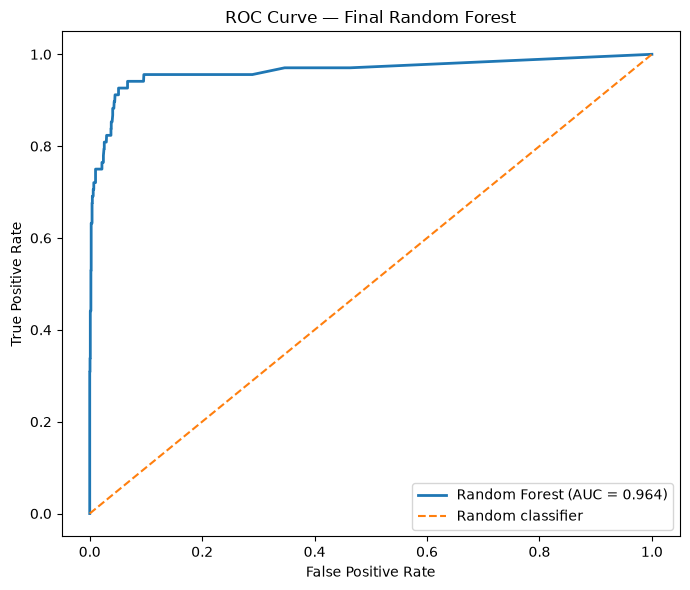

Saved: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\final_roc_curve.png


In [118]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(
    y_lean_test,
    final_test_probabilities
)

roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Final Random Forest")
ax.legend()

plt.tight_layout()

output_path = (
    FIGURES_DIR /
    "final_roc_curve.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

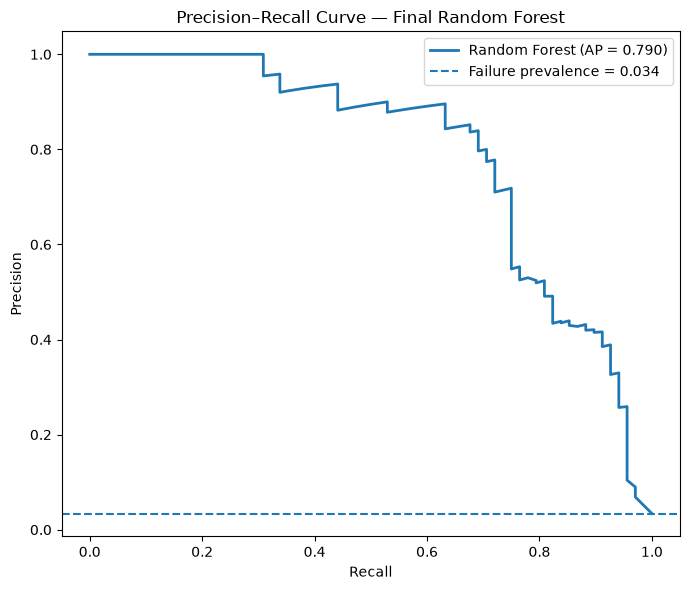

Saved: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\final_precision_recall_curve.png


In [119]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_lean_test,
        final_test_probabilities
    )
)

average_precision = average_precision_score(
    y_lean_test,
    final_test_probabilities
)

failure_prevalence = y_lean_test.mean()

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"Random Forest (AP = {average_precision:.3f})"
)

ax.axhline(
    y=failure_prevalence,
    linestyle="--",
    label=f"Failure prevalence = {failure_prevalence:.3f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(
    "Precision–Recall Curve — Final Random Forest"
)

ax.legend()

plt.tight_layout()

output_path = (
    FIGURES_DIR /
    "final_precision_recall_curve.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

In [120]:
fitted_preprocessor = final_rf.named_steps["preprocessor"]
fitted_rf = final_rf.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print(feature_names)


Number of transformed features: 9
['categorical__Type_H' 'categorical__Type_L' 'categorical__Type_M'
 'numerical__Air temperature [K]' 'numerical__Process temperature [K]'
 'numerical__Rotational speed [rpm]' 'numerical__Torque [Nm]'
 'numerical__Tool wear [min]' 'numerical__Mechanical power [W]']


In [121]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_rf.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df

,Feature,Importance
0,numerical__Rotational speed [rpm],0.230307
1,numerical__Tool wear [min],0.211416
2,numerical__Torque [Nm],0.206739
3,numerical__Mechanical power [W],0.195994
4,numerical__Air temperature [K],0.087913
5,numerical__Process temperature [K],0.052241
6,categorical__Type_L,0.007202
7,categorical__Type_M,0.005532
8,categorical__Type_H,0.002655


In [122]:
feature_importance_plot_df = feature_importance_df.copy()

feature_importance_plot_df["Feature"] = (
    feature_importance_plot_df["Feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numerical__", "", regex=False)
    .str.replace("Type_", "Type = ", regex=False)
)

feature_importance_plot_df

,Feature,Importance
0,Rotational speed [rpm],0.230307
1,Tool wear [min],0.211416
2,Torque [Nm],0.206739
3,Mechanical power [W],0.195994
4,Air temperature [K],0.087913
5,Process temperature [K],0.052241
6,Type = L,0.007202
7,Type = M,0.005532
8,Type = H,0.002655


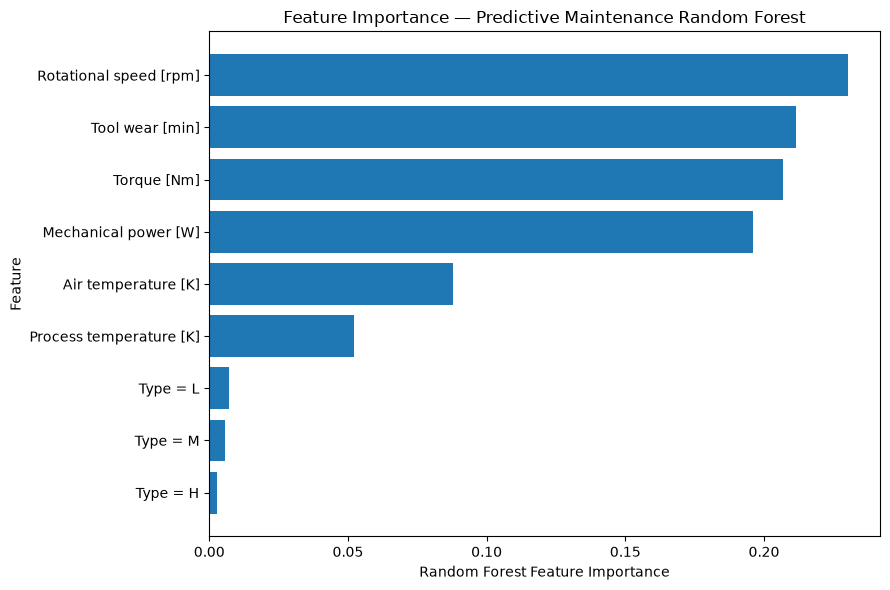

Saved: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\random_forest_feature_importance.png


In [123]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_df = feature_importance_plot_df.sort_values(
    "Importance",
    ascending=True
)

ax.barh(
    plot_df["Feature"],
    plot_df["Importance"]
)

ax.set_xlabel("Random Forest Feature Importance")
ax.set_ylabel("Feature")
ax.set_title(
    "Feature Importance — Predictive Maintenance Random Forest"
)

plt.tight_layout()

output_path = (
    FIGURES_DIR /
    "random_forest_feature_importance.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

### Random Forest Feature Importance

Feature importance was extracted from the fitted Random Forest to investigate
which operating variables contributed most strongly to the model's decisions.

The importance values represent the average reduction in tree impurity
attributed to each feature across the ensemble.

These values describe predictive importance rather than causality.
Furthermore, mechanical power is mathematically derived from torque and
rotational speed,

\[
P = \tau\omega
  = \tau\frac{2\pi N}{60},
\]

so importance may be distributed among correlated physical variables.

The feature-importance analysis therefore provides a global view of model
behavior but should not be interpreted as proof that a particular variable
causes equipment failure.

In [124]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [125]:
X_test_transformed = (
    fitted_preprocessor.transform(X_lean_test)
)

X_test_explain = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_lean_test.index
)

X_test_explain.head()

,categorical__Type_H,categorical__Type_L,categorical__Type_M,numerical__Air temperature [K],numerical__Process temperature [K],numerical__Rotational speed [rpm],numerical__Torque [Nm],numerical__Tool wear [min],numerical__Mechanical power [W]
2997,0.0,1.0,0.0,0.247681,-0.139294,-1.073963,2.265378,0.712410,2.376605
4871,0.0,1.0,0.0,1.850310,1.618248,-0.145641,0.009646,0.429427,0.066084
3858,0.0,1.0,0.0,1.249324,0.942270,0.108543,-0.239882,1.592802,-0.134390
951,1.0,0.0,0.0,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,-0.583229
6463,1.0,0.0,0.0,0.247681,-0.004098,-1.002129,2.035812,-0.089376,2.151190


In [126]:
print("Shape:", X_test_explain.shape)
print("Missing values:", X_test_explain.isna().sum().sum())

Shape: (2000, 9)
Missing values: 0


In [127]:
explainer = shap.TreeExplainer(
    fitted_rf
)

shap_values = explainer(
    X_test_explain
)

print("SHAP values shape:")
print(shap_values.values.shape)

SHAP values shape:
(2000, 9, 2)


In [128]:
shap_failure = shap.Explanation(
    values=shap_values.values[:, :, 1],
    base_values=shap_values.base_values[:, 1],
    data=shap_values.data,
    feature_names=feature_names
)

print("Failure SHAP shape:", shap_failure.values.shape)

Failure SHAP shape: (2000, 9)


In [129]:
clean_feature_names = [
    name
    .replace("categorical__", "")
    .replace("numerical__", "")
    .replace("Type_", "Type = ")
    for name in feature_names
]

shap_failure.feature_names = clean_feature_names

clean_feature_names

['Type = H',
 'Type = L',
 'Type = M',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Mechanical power [W]']

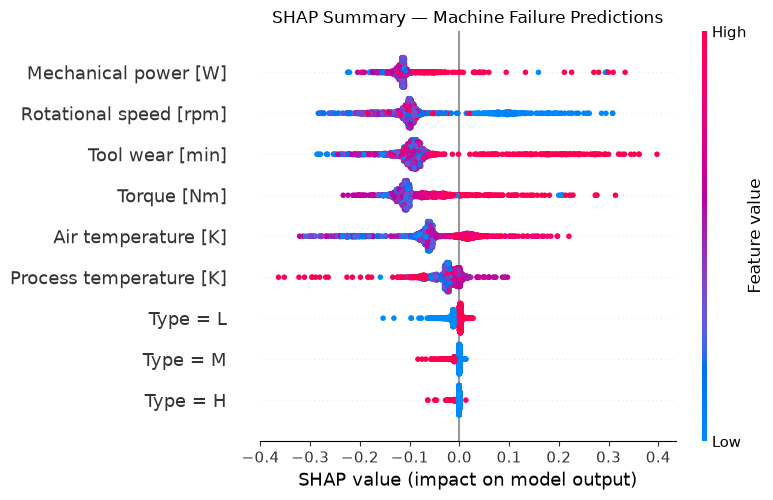

Saved: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\shap_failure_beeswarm.png


In [130]:
shap.plots.beeswarm(
    shap_failure,
    max_display=9,
    show=False
)

plt.title(
    "SHAP Summary — Machine Failure Predictions"
)

plt.tight_layout()

output_path = (
    FIGURES_DIR /
    "shap_failure_beeswarm.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

In [131]:
mean_abs_shap = np.abs(
    shap_failure.values
).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Mean |SHAP|": mean_abs_shap
}).sort_values(
    "Mean |SHAP|",
    ascending=False
).reset_index(drop=True)

shap_importance_df

,Feature,Mean |SHAP|
0,Mechanical power [W],0.114806
1,Rotational speed [rpm],0.112942
2,Tool wear [min],0.106493
3,Torque [Nm],0.096848
4,Air temperature [K],0.069696
5,Process temperature [K],0.026821
6,Type = L,0.008802
7,Type = M,0.004611
8,Type = H,0.001890


In [132]:
true_positive_positions = np.where(
    (y_lean_test.to_numpy() == 1)
    &
    (final_test_predictions == 1)
)[0]

print(
    "Number of true positives:",
    len(true_positive_positions)
)

tp_position = true_positive_positions[0]

print("Selected test position:", tp_position)

print(
    "Predicted failure probability:",
    final_test_probabilities[tp_position]
)

Number of true positives: 46
Selected test position: 21
Predicted failure probability: 0.9957142857142857


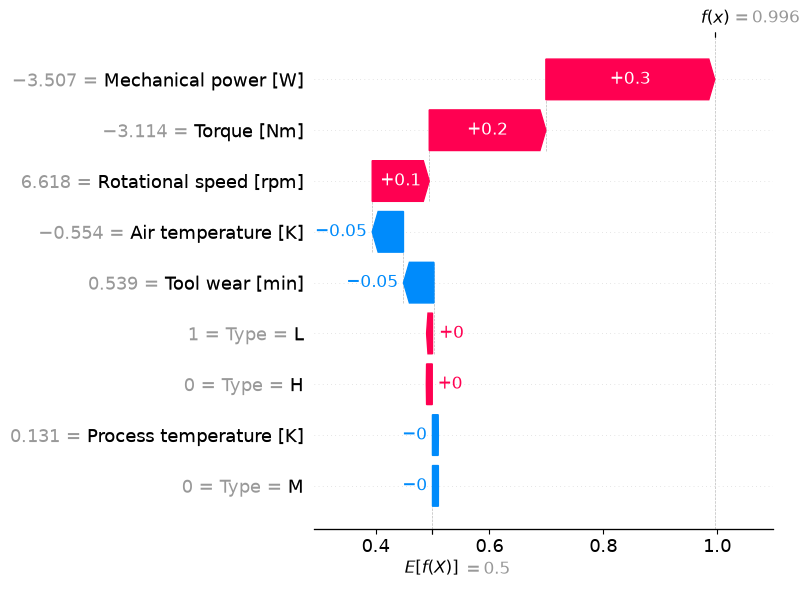

Saved: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\reports\figures\shap_true_positive_waterfall.png


In [133]:
shap.plots.waterfall(
    shap_failure[tp_position],
    max_display=9,
    show=False
)

plt.tight_layout()

output_path = (
    FIGURES_DIR /
    "shap_true_positive_waterfall.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path.resolve())

### SHAP Model Explainability

SHAP (SHapley Additive exPlanations) was applied to the final Random Forest
to explain machine-failure predictions.

For each observation, SHAP decomposes the model output into contributions
from individual input features. Positive SHAP contributions push the model
toward the machine-failure class, while negative contributions push the
prediction away from failure.

Global importance was calculated using mean absolute SHAP values:

\[
I_j =
\frac{1}{n}
\sum_{i=1}^{n}
|\phi_{ij}|
\]

where \(\phi_{ij}\) represents the SHAP contribution of feature \(j\) for
observation \(i\).

SHAP complements the Random Forest's impurity-based feature importance by
providing both global importance and local explanations for individual
machine predictions.

Mechanical power is physically derived from torque and rotational speed, so
their SHAP contributions should not be interpreted as statistically
independent or causal effects. Instead, they collectively characterize the
machine's operating and loading regime.

### SHAP Global Interpretation

The SHAP analysis confirms that the model primarily relies on the machine's
mechanical operating state and accumulated wear.

The four most influential features by mean absolute SHAP value were:

1. Mechanical power
2. Rotational speed
3. Tool wear
4. Torque

Mechanical power ranked first despite being an engineered feature rather
than an original dataset variable. Mechanical power was derived using

\[
P = \tau \omega
  = \tau \frac{2\pi N}{60}.
\]

This provides evidence that physics-informed feature engineering contributed
meaningful predictive information to the machine-learning pipeline.

Mechanical power, rotational speed, and torque should be interpreted jointly
because mechanical power is mathematically dependent on torque and rotational
speed. Their SHAP values therefore describe related aspects of the machine's
operating-load regime rather than independent causal effects.

Tool wear also showed strong predictive influence, representing accumulated
equipment degradation.

Temperature variables had secondary influence, while product-type indicators
had relatively small global SHAP contributions.

The agreement between impurity-based Random Forest importance and SHAP
importance increases confidence that the model's predictions are primarily
driven by physically meaningful operating variables rather than identifier
or leakage features.

In [134]:
selected_machine = X_lean_test.iloc[
    tp_position
].copy()

selected_machine["Actual Failure"] = (
    y_lean_test.iloc[tp_position]
)

selected_machine["Predicted Failure"] = (
    final_test_predictions[tp_position]
)

selected_machine["Failure Probability"] = (
    final_test_probabilities[tp_position]
)

selected_machine

Type                                 L
Air temperature [K]              298.9
Process temperature [K]          310.2
Rotational speed [rpm]            2737
Torque [Nm]                        8.8
Tool wear [min]                    142
Mechanical power [W]       2522.238134
Actual Failure                       1
Predicted Failure                    1
Failure Probability           0.995714
Name: 1391, dtype: object

In [135]:
local_shap_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Feature Value": X_test_explain.iloc[
        tp_position
    ].values,
    "SHAP Value": shap_failure.values[
        tp_position
    ]
})

local_shap_df["Absolute SHAP"] = (
    local_shap_df["SHAP Value"].abs()
)

local_shap_df = local_shap_df.sort_values(
    "Absolute SHAP",
    ascending=False
)

local_shap_df

,Feature,Feature Value,SHAP Value,Absolute SHAP
8,Mechanical power [W],-3.506667,0.296651,0.296651
6,Torque [Nm],-3.114444,0.204903,0.204903
5,Rotational speed [rpm],6.617850,0.100187,0.100187
3,Air temperature [K],-0.553633,-0.054916,0.054916
7,Tool wear [min],0.539476,-0.053505,0.053505
1,Type = L,1.000000,0.002468,0.002468
0,Type = H,0.000000,0.000473,0.000473
4,Process temperature [K],0.131097,-0.000327,0.000327
2,Type = M,0.000000,-0.000085,0.000085


### Local SHAP Case Study — Correctly Detected Failure

A correctly classified machine-failure observation was selected for local
explainability analysis.

The machine operated at:

- Rotational speed: 2737 rpm
- Torque: 8.8 Nm
- Tool wear: 142 min
- Air temperature: 298.9 K
- Process temperature: 310.2 K
- Mechanical power: approximately 2522 W

The final Random Forest assigned a failure probability of approximately
99.57%, and the observation was an actual machine failure.

SHAP showed that the largest positive contributions toward the failure
prediction came from mechanical power, torque, and rotational speed.

The operating point represents an unusual combination of very high
rotational speed, very low torque, and relatively low mechanical power.
This demonstrates that the Random Forest is not relying on a simple
assumption that higher load always implies greater failure risk. Instead,
it can identify nonlinear operating regimes and combinations of sensor
conditions associated with failure.

Air temperature and tool wear contributed in the opposite direction for
this particular observation, partially reducing the predicted failure
output, while product type and process temperature contributed relatively
little.

SHAP values explain the behavior of the predictive model and should not be
interpreted as evidence that any individual feature physically caused the
failure.

In [136]:
from pathlib import Path

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(MODELS_DIR.resolve())

C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\models


In [137]:
import joblib

MODEL_PATH = MODELS_DIR / "predictive_maintenance_rf.joblib"

joblib.dump(final_rf, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH.resolve()}")

Model saved to: C:\Users\dayac\OneDrive\Desktop\Predective_maintenance_AI\models\predictive_maintenance_rf.joblib


In [139]:
loaded_model = joblib.load(MODEL_PATH)

print(type(loaded_model))
print(loaded_model.named_steps.keys())

<class 'sklearn.pipeline.Pipeline'>
dict_keys(['preprocessor', 'classifier'])


In [140]:
print(type(loaded_model))
print(loaded_model.named_steps.keys())

<class 'sklearn.pipeline.Pipeline'>
dict_keys(['preprocessor', 'classifier'])


## Gradient Boosting Experiment — XGBoost

A gradient-boosted tree model is evaluated as an additional nonlinear
ensemble technique.

Unlike Random Forest, which trains many trees largely independently,
gradient boosting constructs trees sequentially so that later trees
focus on correcting errors made by earlier trees.

Because machine failures represent only 3.39% of the dataset, model
selection continues to emphasize PR-AUC, recall, precision, and F1
rather than accuracy.

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Load dataset
DATA_PATH = "../data/raw/ai4i2020.csv"
df = pd.read_csv(DATA_PATH)


# Physics-informed feature engineering
df["Mechanical power [W]"] = (
    df["Torque [Nm]"]
    * (2 * np.pi * df["Rotational speed [rpm]"] / 60)
)


# Final lean feature set
lean_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
]

target = "Machine failure"

X_lean = df[lean_features].copy()
y = df[target].copy()


# Same fixed split used throughout the project
X_lean_train, X_lean_test, y_lean_train, y_lean_test = (
    train_test_split(
        X_lean,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y,
    )
)


# Preprocessing
lean_categorical_features = ["Type"]

lean_numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Mechanical power [W]",
]

lean_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            lean_categorical_features,
        ),
        (
            "numerical",
            StandardScaler(),
            lean_numerical_features,
        ),
    ]
)


# Cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)


# Evaluation metrics
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}


print("Dataset:", df.shape)
print("Training:", X_lean_train.shape)
print("Test:", X_lean_test.shape)
print()
print("Training failures:", y_lean_train.sum())
print("Test failures:", y_lean_test.sum())

Dataset: (10000, 15)
Training: (8000, 7)
Test: (2000, 7)

Training failures: 271
Test failures: 68


In [3]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate


negative_count = (y_lean_train == 0).sum()
positive_count = (y_lean_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training failures:", positive_count)
print("Training non-failures:", negative_count)
print(
    "scale_pos_weight:",
    round(scale_pos_weight, 2),
)

Training failures: 271
Training non-failures: 7729
scale_pos_weight: 28.52


In [4]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

negative_count = (y_lean_train == 0).sum()
positive_count = (y_lean_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training failures:", positive_count)
print("Training non-failures:", negative_count)
print(
    "scale_pos_weight:",
    round(scale_pos_weight, 2),
)

Training failures: 271
Training non-failures: 7729
scale_pos_weight: 28.52


In [5]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", lean_preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=4,
                min_child_weight=1,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [6]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)

xgb_summary = {
    "Precision Mean":
        xgb_cv_results["test_precision"].mean(),

    "Recall Mean":
        xgb_cv_results["test_recall"].mean(),

    "F1 Mean":
        xgb_cv_results["test_f1"].mean(),

    "ROC-AUC Mean":
        xgb_cv_results["test_roc_auc"].mean(),

    "PR-AUC Mean":
        xgb_cv_results["test_pr_auc"].mean(),

    "F1 Std":
        xgb_cv_results["test_f1"].std(),

    "ROC-AUC Std":
        xgb_cv_results["test_roc_auc"].std(),

    "PR-AUC Std":
        xgb_cv_results["test_pr_auc"].std(),
}

pd.Series(xgb_summary).round(4)

Precision Mean    0.6240
Recall Mean       0.8451
F1 Mean           0.7168
ROC-AUC Mean      0.9779
PR-AUC Mean       0.8087
F1 Std            0.0285
ROC-AUC Std       0.0104
PR-AUC Std        0.0419
dtype: float64

In [7]:
from sklearn.model_selection import RandomizedSearchCV


xgb_param_distributions = {
    "classifier__n_estimators": [
        200,
        300,
        500,
        700,
    ],
    "classifier__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.10,
    ],
    "classifier__max_depth": [
        2,
        3,
        4,
        5,
        6,
    ],
    "classifier__min_child_weight": [
        1,
        3,
        5,
        7,
    ],
    "classifier__subsample": [
        0.7,
        0.8,
        0.9,
        1.0,
    ],
    "classifier__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0,
    ],
}


xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
)


xgb_search.fit(
    X_lean_train,
    y_lean_train,
)


print("Best parameters:")
print(xgb_search.best_params_)

print(
    "\nBest CV PR-AUC:",
    round(xgb_search.best_score_, 4),
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'classifier__subsample': 0.9, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1.0}

Best CV PR-AUC: 0.8147


In [8]:
best_xgb = xgb_search.best_estimator_

tuned_xgb_cv = cross_validate(
    best_xgb,
    X_lean_train,
    y_lean_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
)


tuned_xgb_summary = {
    "Precision Mean":
        tuned_xgb_cv["test_precision"].mean(),

    "Recall Mean":
        tuned_xgb_cv["test_recall"].mean(),

    "F1 Mean":
        tuned_xgb_cv["test_f1"].mean(),

    "ROC-AUC Mean":
        tuned_xgb_cv["test_roc_auc"].mean(),

    "PR-AUC Mean":
        tuned_xgb_cv["test_pr_auc"].mean(),

    "F1 Std":
        tuned_xgb_cv["test_f1"].std(),

    "ROC-AUC Std":
        tuned_xgb_cv["test_roc_auc"].std(),

    "PR-AUC Std":
        tuned_xgb_cv["test_pr_auc"].std(),
}


pd.Series(tuned_xgb_summary).round(4)

Precision Mean    0.7531
Recall Mean       0.7933
F1 Mean           0.7720
ROC-AUC Mean      0.9761
PR-AUC Mean       0.8147
F1 Std            0.0341
ROC-AUC Std       0.0124
PR-AUC Std        0.0425
dtype: float64

In [9]:
print(xgb_search.best_params_)
print(xgb_search.best_score_)

{'classifier__subsample': 0.9, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1.0}
0.8146917885154081


In [10]:
print("Best parameters:")
print(xgb_search.best_params_)

print(
    "Best search CV PR-AUC:",
    round(xgb_search.best_score_, 4)
)

Best parameters:
{'classifier__subsample': 0.9, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1.0}
Best search CV PR-AUC: 0.8147
